# Predictive HPC Cluster Monitoring — Rebuilt Feature Engineering Pipeline

**Version 6 · Collector-presence, NFS separation, disk lifecycle and model-input fixes · 2 November 2026**

This notebook builds on V6 and incorporates the latest output audit: 95% collector-presence logic, separate NFS collector diagnostics, time-varying disk-series expectations, and a cleaner resource-only model candidate set.

This notebook rebuilds telemetry features from the historical Prometheus observations in `main.raw_hpc_all` and correlates them with the benchmark annotations in `main.benchmark_events` and `main.benchmark_event_nodes`.

It is designed for **local Jupyter on Windows** and uses DuckDB for large-data processing. It does not scrape the live cloud cluster. It analyses the historical data already stored in your DuckDB database.

## What this notebook produces

- A validated **15-second/node feature table** (the primary resolution for short HPC runs).
- A **one-minute feature table** for longer-term trends.
- Collector availability profiles with a 95% presence threshold, explicit collector coverage, and separate NFS collector diagnostics.
- Benchmark event/node reconciliation, including analysis-only inference of a missing start or end from a known runtime.
- 15-second benchmark correlation based on the overlap of telemetry counter intervals with benchmark windows.
- One-minute benchmark labels based on exact overlap between each one-minute interval and the benchmark window, including a partial-overlap fraction.
- Data-quality reports, plots, Parquet checkpoints and optional DuckDB feature tables.
- Environment snapshot, sparse benchmark-phase flags, null/negative-rate audits, daily distribution summaries, and deterministic stale-output cleanup.

## Important safeguards

1. Raw telemetry and benchmark annotation tables are read-only inputs. Only explicitly named derived feature tables are written, and saving is disabled by default.
2. Counter deltas are calculated per node and full Prometheus label set. Negative deltas are treated as resets. Rates use actual elapsed seconds.
3. Counter-derived CPU, network and disk rates are set to `NULL` when the corresponding interval is incomplete, misaligned, reset, invalid or longer than the configured gap threshold.
4. Network interfaces are selected explicitly. The compute-node default is `enp3s0`, based on the reviewed inventory. ZeroTier, loopback and Docker interfaces are not silently substituted.
5. Persistently-zero collectors are reported separately and excluded from the *dynamic* collector-health calculation. This is a data-driven classification, not proof that a collector is unsupported; review the profile table. In a cloud VM, an unavailable `hwmon` collector is not evidence of a compute-node hardware fault because physical sensor devices may not be exposed to the guest.
6. Collector baseline membership requires both at least one successful observation and presence on at least 95% of the exact node-up scrape timestamps (not just a similar count of timestamps). Per-scrape collector health is reported only when at least 95% of that baseline is observed. Missing collectors are not counted as successful. The NFS collector status is exposed separately and is compared with observed NFS mounts; a zero collector result does not, by itself, prove an NFS storage failure.
7. Swap percentage remains `NULL` when `SwapTotal` is zero because the ratio is undefined when capacity is zero. A separate `swap_configured` field records whether swap capacity exists; it is an audit field, not a useful model input when constant.
8. `cpu_busy_excluding_iowait_pct` is not silently clipped. Out-of-range results are surfaced for investigation and block the final save gate.
9. Benchmark timestamps without a timezone are interpreted using the explicit `EVENT_TIMEZONE_FOR_NAIVE` setting. The default is `Africa/Johannesburg` because the reconciled source logs use SAST. Change it to `UTC` only if the values stored in DuckDB are already UTC-naive.
10. If start or end is missing and a positive runtime is available, the missing bound can be inferred for analysis only. The source tables remain unchanged and the inferred bound is labelled.
11. Events with a suspicious timing record can be excluded from trusted labels without deleting them from the event audit. `HEMELB_EXTRA_20261031` is excluded from label correlation by default until its Slurm timing is verified.
12. Fifteen-second benchmark phases are assigned from scrape-interval overlap. One-minute phases are assigned independently from exact overlap between `[minute_utc, minute_utc + 60s)` and the benchmark window. Partial-minute overlaps are explicitly flagged; a short job is not represented as a full minute of workload.

> **Run from the first cell in a fresh kernel.** Close the DuckDB CLI before running. Use one Python environment for the entire run (Python 3.12 is recommended). Do not train Isolation Forest until the final data-quality gates pass and the benchmark timing exclusions have been reviewed.

**Version 6 review notes:** This version also separates local root-filesystem capacity from NFS-mounted shared storage, preserves unclamped CPU-busy diagnostics while correcting only tiny floating-point roundoff, and adds explicit checks for the six issues in the Gemini review. The core resource Isolation Forest candidate deliberately excludes collector-health context, NFS capacity, and the four network error/drop rates confirmed constant at zero in the audited compute-node data. Those diagnostics remain available in the feature tables and a separate observability context frame.


## 0. Environment and dependencies

Run the installation cell only if an import is missing. In Jupyter, `%pip` installs into the active kernel environment. After installing packages, restart the kernel and run the notebook from the beginning.

**Reproducibility:** the configuration cell records `sys.executable`, Python/package versions, and `sys.executable -m pip freeze`. Use the notebook `%pip` magic if installation is needed; it targets the active kernel. Run all cells from a restarted kernel for a clean execution.


In [1]:
# Optional: run this cell only if a dependency is missing, then restart the kernel.
# IPython's %pip magic installs into the active notebook kernel (unlike an arbitrary
# system-level pip executable). Uncomment only when needed:
# %pip install duckdb pandas numpy pyarrow matplotlib tzdata


## 1. Imports and configuration

The database path below matches the existing Windows project directory. Update it only if the database has moved.

**Timezone setting:** `EVENT_TIMEZONE_FOR_NAIVE` applies only to benchmark timestamp values that have no timezone attached. Raw Prometheus Unix timestamps are always converted from epoch seconds to UTC independently. The notebook preserves any timezone already present in the stored timestamp. Confirm the displayed UTC conversions against source/Slurm logs before setting `EVENT_TIMEZONE_REVIEWED = True`.

In [2]:
# --- Replace Cell In [2] ---
from pathlib import Path
from zoneinfo import ZoneInfo
from datetime import datetime, timezone
import json
import math
import platform
import sys
import warnings
import subprocess

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Paths ----------
DB_PATH = Path(r"C:\Users\Admin\Documents\chpc\capstone project\data\hpc_exploration.duckdb")
DATA_DIR = DB_PATH.parent
OUTPUT_DIR = DATA_DIR / "feature_engineering_duckdb_v6"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load dynamic inventory from nodes.csv and events.csv
NODES_CSV_PATH = OUTPUT_DIR / "nodes.csv" if (OUTPUT_DIR / "nodes.csv").exists() else Path("nodes.csv")
EVENTS_CSV_PATH = OUTPUT_DIR / "events.csv" if (OUTPUT_DIR / "events.csv").exists() else Path("events (1).csv")

nodes_inventory_df = pd.read_csv(NODES_CSV_PATH)
operational_events_df = pd.read_csv(EVENTS_CSV_PATH)

COMPUTE_NODES = sorted(nodes_inventory_df["node_id"].astype(str).unique().tolist())
ALL_NODES = sorted(COMPUTE_NODES + ["headnode"])
CORE_COUNTS = {
    **dict(zip(nodes_inventory_df["node_id"], nodes_inventory_df["cpu_logical_cores"].astype(int))),
    "headnode": 4,
}
CPU_MODES_EXPECTED = 8
EXPECTED_CPU_MODES = ["idle", "iowait", "irq", "nice", "softirq", "steal", "system", "user"]
BUSY_CPU_MODES = ["irq", "nice", "softirq", "steal", "system", "user"]

LONG_GAP_SECONDS = 20.0
ROOT_FS_MOUNTPOINT = "/"
ROOT_FS_FSTYPE = "ext4"
NFS_FSTYPES = ["nfs", "nfs4"]
CPU_PERCENT_ROUNDOFF_TOLERANCE = 1e-9
INTERVAL_ALIGNMENT_TOLERANCE_SECONDS = 0.25
BASELINE_MINUTES = 5
MIN_15S_PHASE_INTERVALS_FOR_DESCRIPTIVE_SUMMARY = 3
MIN_1MIN_PHASE_ROWS_FOR_DESCRIPTIVE_SUMMARY = 2
COLLECTOR_MIN_PRESENCE_PCT = 95.0
COLLECTOR_MIN_ROW_COVERAGE_PCT = 95.0

EVENT_TIMEZONE_FOR_NAIVE = "Africa/Johannesburg"
EVENT_TIMEZONE_REVIEWED = True  # Enabled for V6 export
SAVE_OUTPUTS = True             # Enabled to write Parquet files and DuckDB tables

NETWORK_INTERFACE_BY_NODE = {
    **dict(zip(nodes_inventory_df["node_id"], nodes_inventory_df["network_interface"].astype(str))),
    "headnode": "enp3s0",
}

EVENTS_EXCLUDED_FROM_LABELS = {
    "HEMELB_EXTRA_20261031",
}

## 2. Connect and verify input objects

The connection is opened in read/write mode only because the final optional save section can create derived tables. All source queries are `SELECT` statements. The notebook never updates or replaces `raw_hpc`, `raw_hpc_incremental`, `raw_hpc_all`, `benchmark_events` or `benchmark_event_nodes`.

In [3]:
con = duckdb.connect(str(DB_PATH), read_only=False)

object_inventory = con.execute("""
    SELECT table_name, table_type
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY table_name
""").fetchdf()
display(object_inventory)

required_objects = {"raw_hpc_all", "benchmark_events", "benchmark_event_nodes"}
available_objects = set(object_inventory["table_name"].astype(str))
missing_objects = required_objects - available_objects
if missing_objects:
    raise RuntimeError(f"Required objects missing from schema main: {sorted(missing_objects)}")

print("All required source objects are available.")

,table_name,table_type
0,ascot5_source_files,BASE TABLE
1,benchmark_event_audit_v6,BASE TABLE
2,benchmark_event_exclusions_v6,BASE TABLE
3,benchmark_event_nodes,BASE TABLE
4,benchmark_events,BASE TABLE
5,benchmark_execution_markers_v6,BASE TABLE
6,benchmark_telemetry_15s,BASE TABLE
7,benchmark_telemetry_15s_v6,BASE TABLE
8,benchmark_telemetry_1min,BASE TABLE
9,benchmark_telemetry_1min_v6,BASE TABLE


All required source objects are available.


## 3. Raw telemetry inventory and snapshot

This cell reads only summary statistics from DuckDB. It does not load the 49-million-row source table into Pandas. The exact maximum timestamp is important: it prevents us from confusing the telemetry snapshot with later collector queries or a different database state.

In [4]:
raw_overview = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT node_id) AS node_count,
        MIN(timestamp) AS first_timestamp_unix,
        MAX(timestamp) AS last_timestamp_unix,
        COUNT(DISTINCT metric) AS metric_count
    FROM main.raw_hpc_all
""").fetchdf()
raw_overview["first_timestamp_utc"] = pd.to_datetime(raw_overview["first_timestamp_unix"], unit="s", utc=True)
raw_overview["last_timestamp_utc"] = pd.to_datetime(raw_overview["last_timestamp_unix"], unit="s", utc=True)
display(raw_overview)

metric_inventory = con.execute("""
    SELECT metric, COUNT(*) AS samples,
           COUNT(DISTINCT node_id) AS nodes,
           STRING_AGG(DISTINCT node_id, ', ' ORDER BY node_id) AS node_list,
           MIN(timestamp) AS first_unix,
           MAX(timestamp) AS last_unix
    FROM main.raw_hpc_all
    GROUP BY metric
    ORDER BY metric
""").fetchdf()
metric_inventory["first_utc"] = pd.to_datetime(metric_inventory["first_unix"], unit="s", utc=True)
metric_inventory["last_utc"] = pd.to_datetime(metric_inventory["last_unix"], unit="s", utc=True)
display(metric_inventory)

raw_node_coverage = con.execute("""
    SELECT node_id, COUNT(*) AS raw_rows,
           COUNT(DISTINCT timestamp) AS scrape_timestamps,
           MIN(timestamp) AS first_unix, MAX(timestamp) AS last_unix
    FROM main.raw_hpc_all
    GROUP BY node_id ORDER BY node_id
""").fetchdf()
raw_node_coverage["first_utc"] = pd.to_datetime(raw_node_coverage["first_unix"], unit="s", utc=True)
raw_node_coverage["last_utc"] = pd.to_datetime(raw_node_coverage["last_unix"], unit="s", utc=True)
display(raw_node_coverage)

RAW_ROW_COUNT = int(raw_overview.loc[0, "total_rows"])
RAW_FIRST_UNIX = float(raw_overview.loc[0, "first_timestamp_unix"])
RAW_LAST_UNIX = float(raw_overview.loc[0, "last_timestamp_unix"])

,total_rows,node_count,first_timestamp_unix,last_timestamp_unix,metric_count,first_timestamp_utc,last_timestamp_utc
0,49616574,4,1.792282e+09,1.793491e+09,27,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00


,metric,samples,nodes,node_list,first_unix,last_unix,first_utc,last_utc
0,node_cpu_seconds_total,18062592,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
1,node_disk_io_now,394912,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
2,node_disk_io_time_seconds_total,394912,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
3,node_disk_read_bytes_total,394912,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
4,node_disk_written_bytes_total,394912,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
5,node_filesystem_avail_bytes,1876918,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
6,node_filesystem_size_bytes,1876918,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
7,node_load1,322544,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
8,node_load15,322544,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
9,node_load5,322544,4,"compute001, compute002, compute003, headnode",1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00


,node_id,raw_rows,scrape_timestamps,first_unix,last_unix,first_utc,last_utc
0,compute001,13061640,80639,1.792282e+09,1.793491e+09,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:49.335999966+00:00
1,compute002,12789782,80639,1.792282e+09,1.793491e+09,2026-10-18 00:00:13.588000059+00:00,2026-10-31 23:59:58.588000059+00:00
2,compute003,12789104,80639,1.792282e+09,1.793491e+09,2026-10-18 00:00:08.352999926+00:00,2026-10-31 23:59:53.354000092+00:00
3,headnode,10976048,80640,1.792282e+09,1.793491e+09,2026-10-18 00:00:12.437999964+00:00,2026-10-31 23:59:57.437000036+00:00


## 4. Inspect network interfaces and filesystem mounts

We explicitly inventory network devices and filesystem mounts before feature calculations. The compute-node network interface defaults to `enp3s0`; this is a documented choice from the prior interface inventory, not an automatic guess. If the current inventory no longer contains it, the notebook stops.

Filesystem capacity is **not summed across unrelated mounts**. The feature pipeline separates the local root filesystem (`/`, expected `ext4`) from NFS/NFS4 shared mounts. Other filesystems (tmpfs, overlay, pseudo-filesystems) remain in the inventory but are not mixed into either capacity feature. The NFS collector and filesystem mount statistics are different sources of evidence.

In [5]:
network_inventory = con.execute("""
    SELECT node_id,
           regexp_extract(labels, 'device=([^|]+)', 1) AS device,
           COUNT(*) AS metric_observations,
           COUNT(DISTINCT timestamp) AS scrape_timestamps,
           MIN(timestamp) AS first_unix,
           MAX(timestamp) AS last_unix
    FROM main.raw_hpc_all
    WHERE metric IN ('node_network_receive_bytes_total', 'node_network_transmit_bytes_total')
    GROUP BY node_id, device
    ORDER BY node_id, device
""").fetchdf()
display(network_inventory)

filesystem_inventory = con.execute("""
    SELECT node_id,
           regexp_extract(labels, 'device=([^|]+)', 1) AS device,
           regexp_extract(labels, 'fstype=([^|]+)', 1) AS fstype,
           regexp_extract(labels, 'mountpoint=([^|]+)', 1) AS mountpoint,
           COUNT(DISTINCT timestamp) AS scrape_timestamps
    FROM main.raw_hpc_all
    WHERE metric IN ('node_filesystem_avail_bytes', 'node_filesystem_size_bytes')
    GROUP BY node_id, device, fstype, mountpoint
    ORDER BY node_id, mountpoint, device
""").fetchdf()
filesystem_inventory["filesystem_role"] = np.select(
    [
        filesystem_inventory["mountpoint"].eq(ROOT_FS_MOUNTPOINT)
        & filesystem_inventory["fstype"].str.lower().eq(ROOT_FS_FSTYPE),
        filesystem_inventory["fstype"].str.lower().isin(NFS_FSTYPES),
    ],
    ["LOCAL_ROOT", "NFS_SHARED"],
    default="OTHER_OR_PSEUDO",
)
display(filesystem_inventory)
print("Filesystem role counts:")
display(filesystem_inventory.groupby(["node_id", "filesystem_role"]).size().rename("mount_records").reset_index())

selected_interfaces = {}
for node, interface in NETWORK_INTERFACE_BY_NODE.items():
    if interface is None:
        continue
    observed = set(network_inventory.loc[network_inventory.node_id == node, "device"].dropna().astype(str))
    if interface not in observed:
        raise RuntimeError(f"Configured interface {interface!r} not found for {node}. Observed: {sorted(observed)}. Review NETWORK_INTERFACE_BY_NODE.")
    selected_interfaces[node] = interface

missing_compute_interfaces = sorted(set(COMPUTE_NODES) - set(selected_interfaces))
if missing_compute_interfaces:
    raise RuntimeError(f"No selected network interface for compute nodes: {missing_compute_interfaces}")

print("Selected interfaces:", selected_interfaces)
print("Nodes excluded from interface throughput features:", sorted(set(ALL_NODES) - set(selected_interfaces)))

,node_id,device,metric_observations,scrape_timestamps,first_unix,last_unix
0,compute001,docker0,161274,80637,1.792282e+09,1.793491e+09
1,compute001,enp3s0,161274,80637,1.792282e+09,1.793491e+09
2,compute001,lo,161274,80637,1.792282e+09,1.793491e+09
3,compute002,docker0,161276,80638,1.792282e+09,1.793491e+09
4,compute002,enp3s0,161276,80638,1.792282e+09,1.793491e+09
5,compute002,lo,154592,77296,1.792282e+09,1.793441e+09
6,compute003,docker0,161274,80637,1.792282e+09,1.793491e+09
7,compute003,enp3s0,161274,80637,1.792282e+09,1.793491e+09
8,compute003,lo,154590,77295,1.792282e+09,1.793441e+09
9,headnode,docker0,161264,80632,1.792282e+09,1.793491e+09


,node_id,device,fstype,mountpoint,scrape_timestamps,filesystem_role
0,compute001,/dev/root,ext4,/,80637,LOCAL_ROOT
1,compute001,/dev/vda15,vfat,/boot/efi,80637,OTHER_OR_PSEUDO
2,compute001,headnode:/home/ubuntu,nfs4,/home/ubuntu,25128,NFS_SHARED
3,compute001,headnode:/home/ubuntu,nfs4,/mnt/home,52465,NFS_SHARED
4,compute001,headnode:/shared,nfs4,/mnt/shared,77595,NFS_SHARED
5,compute001,tmpfs,tmpfs,/run,80637,OTHER_OR_PSEUDO
6,compute001,tmpfs,tmpfs,/run/lock,80637,OTHER_OR_PSEUDO
7,compute001,tmpfs,tmpfs,/run/snapd/ns,80637,OTHER_OR_PSEUDO
8,compute001,tmpfs,tmpfs,/run/user/1000,5307,OTHER_OR_PSEUDO
9,compute002,/dev/root,ext4,/,80638,LOCAL_ROOT


Filesystem role counts:


,node_id,filesystem_role,mount_records
0,compute001,LOCAL_ROOT,1
1,compute001,NFS_SHARED,3
2,compute001,OTHER_OR_PSEUDO,5
3,compute002,LOCAL_ROOT,1
4,compute002,NFS_SHARED,3
5,compute002,OTHER_OR_PSEUDO,5
6,compute003,LOCAL_ROOT,1
7,compute003,NFS_SHARED,3
8,compute003,OTHER_OR_PSEUDO,5
9,headnode,LOCAL_ROOT,1


Selected interfaces: {'compute001': 'enp3s0', 'compute002': 'enp3s0', 'compute003': 'enp3s0', 'headnode': 'enp3s0'}
Nodes excluded from interface throughput features: []


## 5. Helper functions and stable data grain

Every feature family must contain at most one record per `(node_id, timestamp)`. The helper also checks that Unix timestamps are numeric and that all datetime displays use UTC.

In [6]:
def query_df(sql: str) -> pd.DataFrame:
    return con.execute(sql).fetchdf()


def check_node_timestamp_unique(df: pd.DataFrame, name: str) -> None:
    if df.empty:
        print(f"{name}: empty result")
        return
    duplicated = df.duplicated(["node_id", "timestamp"], keep=False)
    if duplicated.any():
        examples = df.loc[duplicated, ["node_id", "timestamp"]].head(10)
        raise ValueError(f"{name} has duplicate node/timestamp keys:\n{examples}")
    print(f"{name}: {len(df):,} rows; node/timestamp key is unique")


def to_observation_time(df: pd.DataFrame) -> pd.DataFrame:
    result = df.copy()
    result["timestamp"] = pd.to_numeric(result["timestamp"], errors="coerce")
    result["observation_time"] = pd.to_datetime(result["timestamp"], unit="s", utc=True)
    return result


def sql_literal(value: str) -> str:
    return "'" + str(value).replace("'", "''") + "'"


def normalize_event_timestamp(value, naive_timezone=EVENT_TIMEZONE_FOR_NAIVE):
    """Convert a DB timestamp to UTC; localize naive values using explicit config."""
    if value is None or pd.isna(value):
        return pd.NaT
    ts = pd.Timestamp(value)
    if ts.tzinfo is None:
        ts = ts.tz_localize(ZoneInfo(naive_timezone), ambiguous="NaT", nonexistent="NaT")
    return ts.tz_convert("UTC")


def save_feature_output(df: pd.DataFrame, table_name: str, parquet_name: str) -> None:
    if df is None or df.empty:
        raise ValueError(f"Refusing to save empty output {table_name}")
    parquet_path = OUTPUT_DIR / parquet_name
    df.to_parquet(parquet_path, index=False)
    registration_name = f"_registered_{table_name}"
    con.register(registration_name, df)
    try:
        con.execute(f"CREATE OR REPLACE TABLE main.{table_name} AS SELECT * FROM {registration_name}")
    finally:
        con.unregister(registration_name)
    print(f"Saved {table_name}: {len(df):,} rows → {parquet_path}")

## 6. CPU counter feature engineering

`node_cpu_seconds_total` is a cumulative counter per CPU core and mode. Deltas are computed within `(node_id, full labels)` so one core/mode cannot be differenced against another.

The expected series count is `logical_cores × 8 modes`: 64 for each compute node and 32 for the headnode. A sample is considered usable only when all expected series are present and valid, intervals are aligned within the configured tolerance, no counter reset occurred, and the longest contributing interval is no greater than `LONG_GAP_SECONDS`.

Unlike the previous notebook, long-gap observations are not retained as apparently normal CPU percentages. Their values are set to `NULL` and the quality reason is preserved.

In [7]:
core_values_sql = ",".join(f"({sql_literal(node)}, {cores})" for node, cores in CORE_COUNTS.items())
expected_modes_sql = ",".join(sql_literal(mode) for mode in EXPECTED_CPU_MODES)
busy_modes_sql = ",".join(sql_literal(mode) for mode in BUSY_CPU_MODES)
node_list_sql = ",".join(sql_literal(n) for n in ALL_NODES)

cpu_sql = f"""
WITH node_core_counts AS (
    SELECT * FROM (VALUES {core_values_sql}) AS v(node_id, expected_cores)
),
ordered AS (
    SELECT node_id, timestamp, labels, value,
           TRY_CAST(regexp_extract(labels, 'cpu=([^|]+)', 1) AS INTEGER) AS cpu_core,
           regexp_extract(labels, 'mode=([^|]+)', 1) AS cpu_mode,
           LAG(timestamp) OVER (PARTITION BY node_id, labels ORDER BY timestamp) AS previous_timestamp,
           LAG(value) OVER (PARTITION BY node_id, labels ORDER BY timestamp) AS previous_value
    FROM main.raw_hpc_all
    WHERE metric = 'node_cpu_seconds_total'
      AND node_id IN ({node_list_sql})
),
deltas AS (
    SELECT node_id, timestamp, labels, cpu_core, cpu_mode,
           timestamp - previous_timestamp AS interval_seconds,
           value - previous_value AS cpu_seconds_delta
    FROM ordered
    WHERE previous_timestamp IS NOT NULL AND previous_value IS NOT NULL
),
aggregated AS (
    SELECT node_id, timestamp,
           COUNT(*) AS observed_series,
           COUNT(*) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS valid_series,
           COUNT(*) FILTER (WHERE cpu_seconds_delta < 0) AS counter_reset_series,
           COUNT(*) FILTER (WHERE interval_seconds <= 0) AS invalid_interval_series,
           COUNT(DISTINCT cpu_core) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS observed_cores,
           MIN(cpu_core) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS minimum_cpu_core,
           MAX(cpu_core) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS maximum_cpu_core,
           COUNT(DISTINCT cpu_mode) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS observed_modes,
           COUNT(DISTINCT cpu_mode) FILTER (WHERE cpu_mode IN ({expected_modes_sql}) AND interval_seconds > 0 AND cpu_seconds_delta >= 0) AS expected_modes_observed,
           COUNT(DISTINCT cpu_mode) FILTER (WHERE cpu_mode NOT IN ({expected_modes_sql}) AND interval_seconds > 0 AND cpu_seconds_delta >= 0) AS unexpected_modes_observed,
           MIN(interval_seconds) FILTER (WHERE interval_seconds > 0) AS minimum_interval_seconds,
           MAX(interval_seconds) FILTER (WHERE interval_seconds > 0) AS maximum_interval_seconds,
           AVG(interval_seconds) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS cpu_interval_seconds,
           SUM(cpu_seconds_delta) FILTER (WHERE interval_seconds > 0 AND cpu_seconds_delta >= 0) AS total_cpu_seconds_delta,
           SUM(cpu_seconds_delta) FILTER (WHERE cpu_mode = 'idle' AND interval_seconds > 0 AND cpu_seconds_delta >= 0) AS idle_cpu_seconds_delta,
           SUM(cpu_seconds_delta) FILTER (WHERE cpu_mode = 'iowait' AND interval_seconds > 0 AND cpu_seconds_delta >= 0) AS iowait_cpu_seconds_delta,
           SUM(cpu_seconds_delta) FILTER (WHERE cpu_mode IN ({busy_modes_sql}) AND interval_seconds > 0 AND cpu_seconds_delta >= 0) AS busy_cpu_seconds_delta
    FROM deltas
    GROUP BY node_id, timestamp
),
validated AS (
    SELECT a.*, c.expected_cores,
           c.expected_cores * {CPU_MODES_EXPECTED} AS expected_series,
           CASE
             WHEN a.counter_reset_series > 0 THEN 'COUNTER_RESET'
             WHEN a.invalid_interval_series > 0 THEN 'INVALID_INTERVAL'
             WHEN a.observed_series != c.expected_cores * {CPU_MODES_EXPECTED}
               OR a.valid_series != c.expected_cores * {CPU_MODES_EXPECTED}
               OR a.observed_cores != c.expected_cores
               OR a.minimum_cpu_core != 0
               OR a.maximum_cpu_core != c.expected_cores - 1
               OR a.observed_modes != {CPU_MODES_EXPECTED}
               OR a.expected_modes_observed != {CPU_MODES_EXPECTED}
               OR a.unexpected_modes_observed != 0 THEN 'INCOMPLETE_OR_MISMATCHED_SERIES'
             WHEN a.maximum_interval_seconds - a.minimum_interval_seconds > {INTERVAL_ALIGNMENT_TOLERANCE_SECONDS} THEN 'MISALIGNED_SERIES_INTERVALS'
             WHEN a.maximum_interval_seconds > {LONG_GAP_SECONDS} THEN 'LONG_SCRAPE_GAP'
             ELSE 'GOOD'
           END AS cpu_data_quality
    FROM aggregated a JOIN node_core_counts c USING (node_id)
)
SELECT node_id, timestamp,
       observed_series, valid_series, expected_series,
       observed_cores, expected_cores, minimum_cpu_core, maximum_cpu_core,
       observed_modes, expected_modes_observed, unexpected_modes_observed,
       counter_reset_series, invalid_interval_series,
       cpu_interval_seconds, minimum_interval_seconds AS cpu_minimum_interval_seconds,
       maximum_interval_seconds AS cpu_maximum_interval_seconds,
       total_cpu_seconds_delta, idle_cpu_seconds_delta, iowait_cpu_seconds_delta, busy_cpu_seconds_delta,
       CASE WHEN cpu_data_quality = 'GOOD' AND total_cpu_seconds_delta > 0
                 AND idle_cpu_seconds_delta IS NOT NULL
            THEN 100.0 * (1.0 - idle_cpu_seconds_delta / total_cpu_seconds_delta) END AS cpu_utilisation_pct,
       CASE WHEN cpu_data_quality = 'GOOD' AND total_cpu_seconds_delta > 0
                 AND busy_cpu_seconds_delta IS NOT NULL
            THEN 100.0 * busy_cpu_seconds_delta / total_cpu_seconds_delta END AS cpu_busy_excluding_iowait_pct_raw,
       CASE WHEN cpu_data_quality = 'GOOD' AND total_cpu_seconds_delta > 0
                 AND busy_cpu_seconds_delta IS NOT NULL
            THEN CASE
                 WHEN 100.0 * busy_cpu_seconds_delta / total_cpu_seconds_delta BETWEEN -{CPU_PERCENT_ROUNDOFF_TOLERANCE} AND 0.0 THEN 0.0
                 WHEN 100.0 * busy_cpu_seconds_delta / total_cpu_seconds_delta BETWEEN 100.0 AND 100.0 + {CPU_PERCENT_ROUNDOFF_TOLERANCE} THEN 100.0
                 ELSE 100.0 * busy_cpu_seconds_delta / total_cpu_seconds_delta
            END END AS cpu_busy_excluding_iowait_pct,
       CASE WHEN cpu_data_quality = 'GOOD' AND total_cpu_seconds_delta > 0
                 AND iowait_cpu_seconds_delta IS NOT NULL
            THEN 100.0 * iowait_cpu_seconds_delta / total_cpu_seconds_delta END AS iowait_pct,
       cpu_data_quality
FROM validated
ORDER BY node_id, timestamp
"""

cpu_mode_inventory = query_df("""
    SELECT DISTINCT node_id,
           TRY_CAST(regexp_extract(labels, 'cpu=([^|]+)', 1) AS INTEGER) AS cpu_core,
           regexp_extract(labels, 'mode=([^|]+)', 1) AS cpu_mode
    FROM main.raw_hpc_all
    WHERE metric = 'node_cpu_seconds_total'
    ORDER BY node_id, cpu_core, cpu_mode
""")
print("Observed CPU core/mode label inventory:")
display(cpu_mode_inventory.groupby("node_id").agg(
    core_count=("cpu_core", "nunique"),
    min_core=("cpu_core", "min"),
    max_core=("cpu_core", "max"),
    mode_count=("cpu_mode", "nunique"),
    modes=("cpu_mode", lambda s: ", ".join(sorted(s.dropna().unique())))
).reset_index())

cpu_features = to_observation_time(query_df(cpu_sql))
check_node_timestamp_unique(cpu_features, "CPU features")
display(cpu_features.head())

Observed CPU core/mode label inventory:


,node_id,core_count,min_core,max_core,mode_count,modes
0,compute001,8,0,7,8,"idle, iowait, irq, nice, softirq, steal, syste..."
1,compute002,8,0,7,8,"idle, iowait, irq, nice, softirq, steal, syste..."
2,compute003,8,0,7,8,"idle, iowait, irq, nice, softirq, steal, syste..."
3,headnode,4,0,3,8,"idle, iowait, irq, nice, softirq, steal, syste..."


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU features: 322,540 rows; node/timestamp key is unique


,node_id,timestamp,observed_series,valid_series,expected_series,observed_cores,expected_cores,minimum_cpu_core,maximum_cpu_core,observed_modes,...,total_cpu_seconds_delta,idle_cpu_seconds_delta,iowait_cpu_seconds_delta,busy_cpu_seconds_delta,cpu_utilisation_pct,cpu_busy_excluding_iowait_pct_raw,cpu_busy_excluding_iowait_pct,iowait_pct,cpu_data_quality,observation_time
0,compute001,1.792282e+09,64,64,64,8,8,0,7,8,...,119.97,119.79,0.04,0.14,0.150038,0.116696,0.116696,0.033342,GOOD,2026-10-18 00:00:19.335999966+00:00
1,compute001,1.792282e+09,64,64,64,8,8,0,7,8,...,120.03,120.00,0.00,0.03,0.024994,0.024994,0.024994,0.000000,GOOD,2026-10-18 00:00:34.335999966+00:00
2,compute001,1.792282e+09,64,64,64,8,8,0,7,8,...,119.98,119.95,0.01,0.02,0.025004,0.016669,0.016669,0.008335,GOOD,2026-10-18 00:00:49.335999966+00:00
3,compute001,1.792282e+09,64,64,64,8,8,0,7,8,...,119.95,119.94,0.00,0.01,0.008337,0.008337,0.008337,0.000000,GOOD,2026-10-18 00:01:04.335999966+00:00
4,compute001,1.792282e+09,64,64,64,8,8,0,7,8,...,120.03,120.00,0.00,0.03,0.024994,0.024994,0.024994,0.000000,GOOD,2026-10-18 00:01:19.335999966+00:00


## 7. CPU quality audit — do not clip unexplained values

This cell reports the exact minimum/maximum, node distribution and data-quality categories. Values outside `[0, 100]` are displayed with their source deltas and interval diagnostics. No clipping or replacement is performed.

In [8]:
cpu_quality_summary = cpu_features.groupby("node_id", as_index=False).agg(
    rows=("timestamp", "size"),
    valid_cpu_rows=("cpu_utilisation_pct", "count"),
    mean_cpu_pct=("cpu_utilisation_pct", "mean"),
    min_cpu_pct=("cpu_utilisation_pct", "min"),
    max_cpu_pct=("cpu_utilisation_pct", "max"),
    invalid_busy_rows=("cpu_busy_excluding_iowait_pct_raw", lambda s: int((s.notna() & ((s < -CPU_PERCENT_ROUNDOFF_TOLERANCE) | (s > 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE))).sum())),
    tiny_roundoff_rows=("cpu_busy_excluding_iowait_pct_raw", lambda s: int((s.notna() & (((s < 0) & (s >= -CPU_PERCENT_ROUNDOFF_TOLERANCE)) | ((s > 100) & (s <= 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE)))).sum())),
    counter_reset_rows=("counter_reset_series", lambda s: int((s > 0).sum())),
    long_gap_rows=("cpu_data_quality", lambda s: int((s == "LONG_SCRAPE_GAP").sum())),
)
display(cpu_quality_summary)
print("CPU data-quality categories:")
display(cpu_features.groupby(["node_id", "cpu_data_quality"], dropna=False).size().rename("rows").reset_index())

cpu_busy_raw = cpu_features["cpu_busy_excluding_iowait_pct_raw"]
cpu_busy_invalid = cpu_features.loc[
    cpu_busy_raw.notna()
    & ((cpu_busy_raw < -CPU_PERCENT_ROUNDOFF_TOLERANCE)
       | (cpu_busy_raw > 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE))
].copy()
cpu_busy_roundoff = cpu_features.loc[
    cpu_busy_raw.notna()
    & (((cpu_busy_raw < 0) & (cpu_busy_raw >= -CPU_PERCENT_ROUNDOFF_TOLERANCE))
       | ((cpu_busy_raw > 100) & (cpu_busy_raw <= 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE)))
].copy()
print("Raw CPU busy percentage outside [0,100] beyond roundoff tolerance:", len(cpu_busy_invalid))
print("Tiny floating-point values clamped:", len(cpu_busy_roundoff))
if cpu_busy_raw.notna().any():
    print("Raw CPU busy minimum:", cpu_busy_raw.min())
    print("Raw CPU busy maximum:", cpu_busy_raw.max())
if not cpu_busy_invalid.empty:
    display(cpu_busy_invalid[[
        "node_id", "observation_time", "cpu_busy_excluding_iowait_pct_raw",
        "total_cpu_seconds_delta", "idle_cpu_seconds_delta", "iowait_cpu_seconds_delta", "busy_cpu_seconds_delta",
        "observed_cores", "observed_modes", "expected_modes_observed",
        "cpu_interval_seconds", "cpu_minimum_interval_seconds", "cpu_maximum_interval_seconds",
        "observed_series", "valid_series", "cpu_data_quality"
    ]].head(100))
CPU_RANGE_OK = cpu_busy_invalid.empty and cpu_features["cpu_busy_excluding_iowait_pct"].dropna().between(0, 100).all() and cpu_features["cpu_utilisation_pct"].dropna().between(0, 100).all() and cpu_features["iowait_pct"].dropna().between(0, 100).all()
print("CPU percentage range gate:", CPU_RANGE_OK)

,node_id,rows,valid_cpu_rows,mean_cpu_pct,min_cpu_pct,max_cpu_pct,invalid_busy_rows,tiny_roundoff_rows,counter_reset_rows,long_gap_rows
0,compute001,80636,80634,0.615618,0.000000,100.000000,0,5,0,2
1,compute002,80637,80635,0.561570,0.000000,100.000000,0,5,0,2
2,compute003,80636,80633,0.518187,0.000000,100.000000,0,6,0,3
3,headnode,80631,80630,0.482880,0.066845,99.665999,0,0,0,1


CPU data-quality categories:


,node_id,cpu_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute002,GOOD,80635
3,compute002,LONG_SCRAPE_GAP,2
4,compute003,GOOD,80633
5,compute003,LONG_SCRAPE_GAP,3
6,headnode,GOOD,80630
7,headnode,LONG_SCRAPE_GAP,1


Raw CPU busy percentage outside [0,100] beyond roundoff tolerance: 0
Tiny floating-point values clamped: 16
Raw CPU busy minimum: 0.0
Raw CPU busy maximum: 100.00000000000001
CPU percentage range gate: True


## 8. Memory feature engineering

Memory metrics are gauges and are not differenced. Used memory is calculated as `MemTotal - MemAvailable`, which accounts for reclaimable cache and buffers. Swap utilisation is calculated only when `SwapTotal > 0`; when swap is absent or disabled, the percentage remains `NULL`.

In [9]:
memory_sql = """
WITH memory_pivot AS (
    SELECT node_id, timestamp,
           MAX(value) FILTER (WHERE metric = 'node_memory_MemTotal_bytes') AS mem_total_bytes,
           MAX(value) FILTER (WHERE metric = 'node_memory_MemAvailable_bytes') AS mem_available_bytes,
           MAX(value) FILTER (WHERE metric = 'node_memory_MemFree_bytes') AS mem_free_bytes,
           MAX(value) FILTER (WHERE metric = 'node_memory_SwapTotal_bytes') AS swap_total_bytes,
           MAX(value) FILTER (WHERE metric = 'node_memory_SwapFree_bytes') AS swap_free_bytes,
           COUNT(DISTINCT metric) AS memory_metrics_present
    FROM main.raw_hpc_all
    WHERE metric IN (
        'node_memory_MemTotal_bytes', 'node_memory_MemAvailable_bytes',
        'node_memory_MemFree_bytes', 'node_memory_SwapTotal_bytes',
        'node_memory_SwapFree_bytes'
    )
    GROUP BY node_id, timestamp
)
SELECT *,
       mem_total_bytes - mem_available_bytes AS mem_used_bytes,
       (mem_total_bytes - mem_available_bytes) / 1073741824.0 AS mem_used_gib,
       mem_available_bytes / 1073741824.0 AS mem_available_gib,
       mem_free_bytes / 1073741824.0 AS mem_free_gib,
       CASE WHEN mem_total_bytes > 0 AND mem_available_bytes BETWEEN 0 AND mem_total_bytes
            THEN 100.0 * (mem_total_bytes - mem_available_bytes) / mem_total_bytes END AS memory_used_pct,
       CASE WHEN mem_total_bytes > 0 AND mem_available_bytes BETWEEN 0 AND mem_total_bytes
            THEN 100.0 * mem_available_bytes / mem_total_bytes END AS memory_available_pct,
       CASE WHEN mem_total_bytes > 0 AND mem_free_bytes BETWEEN 0 AND mem_total_bytes
            THEN 100.0 * mem_free_bytes / mem_total_bytes END AS memory_free_pct,
       CASE
           WHEN swap_total_bytes > 0 THEN 1
           WHEN swap_total_bytes = 0 AND swap_free_bytes = 0 THEN 0
           ELSE NULL
       END AS swap_configured,
       swap_total_bytes - swap_free_bytes AS swap_used_bytes,
       -- A percentage with zero total capacity is undefined, not 0% used.
       CASE WHEN swap_total_bytes > 0 AND swap_free_bytes BETWEEN 0 AND swap_total_bytes
            THEN 100.0 * (swap_total_bytes - swap_free_bytes) / swap_total_bytes END AS swap_used_pct
FROM memory_pivot
ORDER BY node_id, timestamp
"""
memory_features = to_observation_time(query_df(memory_sql))
check_node_timestamp_unique(memory_features, "Memory features")
display(memory_features.head())
print("Swap configured values:")
display(memory_features["swap_configured"].value_counts(dropna=False).to_frame("rows"))
print("Swap percentage non-null rows:", int(memory_features["swap_used_pct"].notna().sum()))
print("Note: a 0-byte swap device has undefined utilisation; swap_used_pct remains NULL and is excluded from model inputs.")

Memory features: 322,544 rows; node/timestamp key is unique


,node_id,timestamp,mem_total_bytes,mem_available_bytes,mem_free_bytes,swap_total_bytes,swap_free_bytes,memory_metrics_present,mem_used_bytes,mem_used_gib,mem_available_gib,mem_free_gib,memory_used_pct,memory_available_pct,memory_free_pct,swap_configured,swap_used_bytes,swap_used_pct,observation_time
0,compute001,1.792282e+09,1.679408e+10,1.635380e+10,1.414037e+10,0.0,0.0,5,440287232.0,0.410049,15.230659,13.169243,2.621681,97.378319,84.198504,0,0.0,NaN,2026-10-18 00:00:04.335999966+00:00
1,compute001,1.792282e+09,1.679408e+10,1.635102e+10,1.413730e+10,0.0,0.0,5,443064320.0,0.412636,15.228073,13.166389,2.638217,97.361783,84.180260,0,0.0,NaN,2026-10-18 00:00:19.335999966+00:00
2,compute001,1.792282e+09,1.679408e+10,1.635102e+10,1.413730e+10,0.0,0.0,5,443060224.0,0.412632,15.228077,13.166389,2.638192,97.361808,84.180260,0,0.0,NaN,2026-10-18 00:00:34.335999966+00:00
3,compute001,1.792282e+09,1.679408e+10,1.635104e+10,1.413730e+10,0.0,0.0,5,443047936.0,0.412621,15.228088,13.166389,2.638119,97.361881,84.180260,0,0.0,NaN,2026-10-18 00:00:49.335999966+00:00
4,compute001,1.792282e+09,1.679408e+10,1.635104e+10,1.413730e+10,0.0,0.0,5,443047936.0,0.412621,15.228088,13.166389,2.638119,97.361881,84.180260,0,0.0,NaN,2026-10-18 00:01:04.335999966+00:00


Swap configured values:


,rows
swap_configured,
0,322544


Swap percentage non-null rows: 0
Note: a 0-byte swap device has undefined utilisation; swap_used_pct remains NULL and is excluded from model inputs.


## 9. Network counter feature engineering

The selected interface's receive/transmit bytes, errors and drops are cumulative counters. TCP retransmissions are also a cumulative counter. Every delta is converted to a **per-second rate** using that series' actual elapsed time. Raw deltas are retained as diagnostics.

A node/timestamp network record is considered `GOOD` only when every counter series observed in the network inventory is present and valid at that timestamp, with no resets, invalid intervals or interval longer than `LONG_GAP_SECONDS`. Network rate features are `NULL` otherwise. This avoids treating partial sums or long-gap deltas as ordinary throughput.

In [10]:
interface_values_sql = ",".join(
    f"({sql_literal(node)}, {sql_literal(device)})" for node, device in selected_interfaces.items()
)
network_metrics = [
    "node_network_receive_bytes_total", "node_network_transmit_bytes_total",
    "node_network_receive_errs_total", "node_network_transmit_errs_total",
    "node_network_receive_drop_total", "node_network_transmit_drop_total",
    "node_netstat_Tcp_RetransSegs",
]
network_interface_metrics = [m for m in network_metrics if m != "node_netstat_Tcp_RetransSegs"]
network_metrics_sql = ",".join(sql_literal(m) for m in network_interface_metrics)

network_sql = f"""
WITH interface_map AS (
    SELECT * FROM (VALUES {interface_values_sql}) AS v(node_id, selected_device)
),
base AS (
    SELECT r.node_id, r.timestamp, r.metric, COALESCE(r.labels, '') AS labels, r.value
    FROM main.raw_hpc_all r
    JOIN interface_map i ON r.node_id = i.node_id
    WHERE r.metric = 'node_netstat_Tcp_RetransSegs'
       OR (r.metric IN ({network_metrics_sql})
           AND regexp_extract(r.labels, 'device=([^|]+)', 1) = i.selected_device)
),
expected AS (
    SELECT node_id, COUNT(DISTINCT metric || '|' || labels) AS expected_counter_series
    FROM base GROUP BY node_id
),
ordered AS (
    SELECT node_id, timestamp, metric, labels, value,
           LAG(timestamp) OVER (PARTITION BY node_id, metric, labels ORDER BY timestamp) AS previous_timestamp,
           LAG(value) OVER (PARTITION BY node_id, metric, labels ORDER BY timestamp) AS previous_value
    FROM base
),
deltas AS (
    SELECT node_id, timestamp, metric, labels,
           timestamp - previous_timestamp AS interval_seconds,
           value - previous_value AS counter_delta
    FROM ordered
    WHERE previous_timestamp IS NOT NULL AND previous_value IS NOT NULL
),
aggregated AS (
    SELECT node_id, timestamp,
           COUNT(DISTINCT metric || '|' || labels) AS observed_counter_series,
           COUNT(*) FILTER (WHERE interval_seconds > 0 AND counter_delta >= 0) AS valid_counter_series,
           COUNT(*) FILTER (WHERE counter_delta < 0) AS counter_reset_series,
           COUNT(*) FILTER (WHERE interval_seconds <= 0) AS invalid_interval_series,
           MIN(interval_seconds) FILTER (WHERE interval_seconds > 0) AS minimum_interval_seconds,
           MAX(interval_seconds) FILTER (WHERE interval_seconds > 0) AS maximum_interval_seconds,
           AVG(interval_seconds) FILTER (WHERE interval_seconds > 0 AND counter_delta >= 0) AS network_interval_seconds,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_receive_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_bytes_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_receive_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_bytes_per_second,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_transmit_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_bytes_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_transmit_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_bytes_per_second,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_receive_errs_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_errors_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_receive_errs_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_errors_per_s,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_transmit_errs_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_errors_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_transmit_errs_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_errors_per_s,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_receive_drop_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_drops_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_receive_drop_total' AND interval_seconds > 0 AND counter_delta >= 0) AS rx_drops_per_s,
           SUM(counter_delta) FILTER (WHERE metric = 'node_network_transmit_drop_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_drops_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_network_transmit_drop_total' AND interval_seconds > 0 AND counter_delta >= 0) AS tx_drops_per_s,
           SUM(counter_delta) FILTER (WHERE metric = 'node_netstat_Tcp_RetransSegs' AND interval_seconds > 0 AND counter_delta >= 0) AS tcp_retrans_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_netstat_Tcp_RetransSegs' AND interval_seconds > 0 AND counter_delta >= 0) AS tcp_retrans_per_s
    FROM deltas GROUP BY node_id, timestamp
),
joined AS (
    SELECT a.*, e.expected_counter_series
    FROM aggregated a JOIN expected e USING (node_id)
),
quality AS (
    SELECT *,
      CASE
        WHEN counter_reset_series > 0 THEN 'COUNTER_RESET'
        WHEN invalid_interval_series > 0 THEN 'INVALID_INTERVAL'
        WHEN observed_counter_series != expected_counter_series OR valid_counter_series != expected_counter_series THEN 'INCOMPLETE_COUNTER_SERIES'
        WHEN maximum_interval_seconds > {LONG_GAP_SECONDS} THEN 'LONG_SCRAPE_GAP'
        ELSE 'GOOD'
      END AS network_data_quality
    FROM joined
)
SELECT node_id, timestamp, expected_counter_series, observed_counter_series,
       valid_counter_series, counter_reset_series AS network_counter_reset_series,
       invalid_interval_series AS network_invalid_interval_series,
       network_interval_seconds, minimum_interval_seconds AS network_minimum_interval_seconds,
       maximum_interval_seconds AS network_maximum_interval_seconds,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_bytes_delta END AS rx_bytes_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_bytes_delta END AS tx_bytes_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_bytes_per_second / 1048576.0 END AS network_rx_mib_s,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_bytes_per_second / 1048576.0 END AS network_tx_mib_s,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_errors_delta END AS rx_errors_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_errors_per_s END AS rx_errors_per_s,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_errors_delta END AS tx_errors_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_errors_per_s END AS tx_errors_per_s,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_drops_delta END AS rx_drops_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN rx_drops_per_s END AS rx_drops_per_s,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_drops_delta END AS tx_drops_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN tx_drops_per_s END AS tx_drops_per_s,
       CASE WHEN network_data_quality = 'GOOD' THEN tcp_retrans_delta END AS tcp_retrans_delta,
       CASE WHEN network_data_quality = 'GOOD' THEN tcp_retrans_per_s END AS tcp_retrans_per_s,
       network_data_quality
FROM quality ORDER BY node_id, timestamp
"""
network_features = to_observation_time(query_df(network_sql))
check_node_timestamp_unique(network_features, "Network features")
display(network_features.head())
display(network_features.groupby(["node_id", "network_data_quality"], dropna=False).size().rename("rows").reset_index())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Network features: 322,540 rows; node/timestamp key is unique


,node_id,timestamp,expected_counter_series,observed_counter_series,valid_counter_series,network_counter_reset_series,network_invalid_interval_series,network_interval_seconds,network_minimum_interval_seconds,network_maximum_interval_seconds,...,tx_errors_delta,tx_errors_per_s,rx_drops_delta,rx_drops_per_s,tx_drops_delta,tx_drops_per_s,tcp_retrans_delta,tcp_retrans_per_s,network_data_quality,observation_time
0,compute001,1.792282e+09,7,7,7,0,0,15.0,15.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GOOD,2026-10-18 00:00:19.335999966+00:00
1,compute001,1.792282e+09,7,7,7,0,0,15.0,15.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GOOD,2026-10-18 00:00:34.335999966+00:00
2,compute001,1.792282e+09,7,7,7,0,0,15.0,15.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GOOD,2026-10-18 00:00:49.335999966+00:00
3,compute001,1.792282e+09,7,7,7,0,0,15.0,15.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GOOD,2026-10-18 00:01:04.335999966+00:00
4,compute001,1.792282e+09,7,7,7,0,0,15.0,15.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GOOD,2026-10-18 00:01:19.335999966+00:00


,node_id,network_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute002,GOOD,80635
3,compute002,LONG_SCRAPE_GAP,2
4,compute003,GOOD,80633
5,compute003,LONG_SCRAPE_GAP,3
6,headnode,GOOD,80630
7,headnode,LONG_SCRAPE_GAP,1


## 10. Disk counter feature engineering

Disk read/write bytes and I/O-time counters are converted to per-second rates. `node_disk_io_now` remains a gauge. The long-gap check uses the **maximum contributing interval**, not the average. All disk rates are set to `NULL` when a node/timestamp has a reset, invalid interval, incomplete expected series or long gap.

`disk_io_time_pct_sum` is the sum of device busy-time percentages and can exceed 100% when multiple devices are included. It is not a single-device utilisation percentage.

In [11]:
disk_sql = f"""
WITH base AS (
    SELECT node_id, timestamp, metric, COALESCE(labels, '') AS labels, value,
           regexp_extract(labels, 'device=([^|]+)', 1) AS disk_device
    FROM main.raw_hpc_all
    WHERE metric IN ('node_disk_read_bytes_total', 'node_disk_written_bytes_total', 'node_disk_io_time_seconds_total')
),
ordered AS (
    SELECT node_id, timestamp, metric, labels, value, disk_device,
           LAG(timestamp) OVER (PARTITION BY node_id, metric, labels ORDER BY timestamp) AS previous_timestamp,
           LAG(value) OVER (PARTITION BY node_id, metric, labels ORDER BY timestamp) AS previous_value
    FROM base
),
deltas AS (
    SELECT node_id, timestamp, metric, labels, disk_device,
           timestamp - previous_timestamp AS interval_seconds,
           value - previous_value AS counter_delta
    FROM ordered
    WHERE previous_timestamp IS NOT NULL AND previous_value IS NOT NULL
),
series_lifecycle AS (
    -- A series becomes expected only once it has enough history to produce its first delta.
    -- This handles devices attached after monitoring began without hiding later missing samples.
    SELECT node_id, disk_device, metric, labels,
           MIN(timestamp) AS first_delta_timestamp
    FROM deltas
    GROUP BY node_id, disk_device, metric, labels
),
aggregated AS (
    SELECT node_id, timestamp,
           COUNT(DISTINCT metric || '|' || labels) AS observed_disk_counter_series,
           COUNT(*) FILTER (WHERE interval_seconds > 0 AND counter_delta >= 0) AS valid_disk_counter_series,
           COUNT(*) FILTER (WHERE counter_delta < 0) AS disk_counter_resets,
           COUNT(*) FILTER (WHERE interval_seconds <= 0) AS invalid_interval_series,
           COUNT(DISTINCT disk_device) AS disk_devices_observed,
           MIN(interval_seconds) FILTER (WHERE interval_seconds > 0) AS minimum_interval_seconds,
           MAX(interval_seconds) FILTER (WHERE interval_seconds > 0) AS maximum_interval_seconds,
           AVG(interval_seconds) FILTER (WHERE interval_seconds > 0 AND counter_delta >= 0) AS disk_interval_seconds,
           SUM(counter_delta) FILTER (WHERE metric = 'node_disk_read_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS read_bytes_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_disk_read_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS read_bytes_per_second,
           SUM(counter_delta) FILTER (WHERE metric = 'node_disk_written_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS written_bytes_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_disk_written_bytes_total' AND interval_seconds > 0 AND counter_delta >= 0) AS written_bytes_per_second,
           SUM(counter_delta) FILTER (WHERE metric = 'node_disk_io_time_seconds_total' AND interval_seconds > 0 AND counter_delta >= 0) AS io_time_seconds_delta,
           SUM(counter_delta / NULLIF(interval_seconds, 0)) FILTER (WHERE metric = 'node_disk_io_time_seconds_total' AND interval_seconds > 0 AND counter_delta >= 0) AS io_time_seconds_per_second
    FROM deltas GROUP BY node_id, timestamp
),
expected_at_timestamp AS (
    SELECT a.node_id, a.timestamp,
           COUNT(l.metric) AS expected_disk_counter_series,
           COUNT(DISTINCT l.disk_device) AS expected_disk_devices
    FROM aggregated a
    LEFT JOIN series_lifecycle l
      ON l.node_id = a.node_id
     AND l.first_delta_timestamp <= a.timestamp
    GROUP BY a.node_id, a.timestamp
),
io_now AS (
    SELECT node_id, timestamp, SUM(value) AS disk_io_now
    FROM main.raw_hpc_all WHERE metric = 'node_disk_io_now'
    GROUP BY node_id, timestamp
),
joined AS (
    SELECT a.*, e.expected_disk_counter_series, e.expected_disk_devices, n.disk_io_now
    FROM aggregated a
    JOIN expected_at_timestamp e USING (node_id, timestamp)
    LEFT JOIN io_now n USING (node_id, timestamp)
),
quality AS (
    SELECT *,
      CASE
        WHEN disk_counter_resets > 0 THEN 'COUNTER_RESET'
        WHEN invalid_interval_series > 0 THEN 'INVALID_INTERVAL'
        WHEN observed_disk_counter_series != expected_disk_counter_series OR valid_disk_counter_series != expected_disk_counter_series THEN 'INCOMPLETE_COUNTER_SERIES'
        WHEN maximum_interval_seconds > {LONG_GAP_SECONDS} THEN 'LONG_SCRAPE_GAP'
        ELSE 'GOOD'
      END AS disk_data_quality
    FROM joined
)
SELECT node_id, timestamp, expected_disk_counter_series, observed_disk_counter_series,
       valid_disk_counter_series, expected_disk_devices, disk_devices_observed,
       disk_counter_resets, invalid_interval_series AS disk_invalid_interval_series,
       disk_interval_seconds, minimum_interval_seconds AS disk_minimum_interval_seconds,
       maximum_interval_seconds AS disk_maximum_interval_seconds,
       disk_io_now,
       CASE WHEN disk_data_quality = 'GOOD' THEN read_bytes_delta END AS read_bytes_delta,
       CASE WHEN disk_data_quality = 'GOOD' THEN written_bytes_delta END AS written_bytes_delta,
       CASE WHEN disk_data_quality = 'GOOD' THEN read_bytes_per_second / 1048576.0 END AS disk_read_mib_s,
       CASE WHEN disk_data_quality = 'GOOD' THEN written_bytes_per_second / 1048576.0 END AS disk_write_mib_s,
       CASE WHEN disk_data_quality = 'GOOD' THEN 100.0 * io_time_seconds_per_second END AS disk_io_time_pct_sum,
       disk_data_quality
FROM quality ORDER BY node_id, timestamp
"""
disk_features = to_observation_time(query_df(disk_sql))
check_node_timestamp_unique(disk_features, "Disk features")
print("Disk quality counts by node:")
display(disk_features.groupby(["node_id", "disk_data_quality"], dropna=False).size().rename("rows").reset_index())
print("Dynamic expected disk devices / counter series by node:")
display(disk_features.groupby("node_id").agg(
    expected_devices_min=("expected_disk_devices", "min"),
    expected_devices_max=("expected_disk_devices", "max"),
    expected_series_min=("expected_disk_counter_series", "min"),
    expected_series_max=("expected_disk_counter_series", "max"),
    observed_series_max=("observed_disk_counter_series", "max"),
).reset_index())
display(disk_features.head())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Disk features: 322,540 rows; node/timestamp key is unique
Disk quality counts by node:


,node_id,disk_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute002,GOOD,80635
3,compute002,LONG_SCRAPE_GAP,2
4,compute003,GOOD,80633
5,compute003,LONG_SCRAPE_GAP,3
6,headnode,GOOD,80630
7,headnode,LONG_SCRAPE_GAP,1


Dynamic expected disk devices / counter series by node:


,node_id,expected_devices_min,expected_devices_max,expected_series_min,expected_series_max,observed_series_max
0,compute001,1,1,3,3,3
1,compute002,1,1,3,3,3
2,compute003,1,1,3,3,3
3,headnode,1,2,3,6,6


,node_id,timestamp,expected_disk_counter_series,observed_disk_counter_series,valid_disk_counter_series,expected_disk_devices,disk_devices_observed,disk_counter_resets,disk_invalid_interval_series,disk_interval_seconds,disk_minimum_interval_seconds,disk_maximum_interval_seconds,disk_io_now,read_bytes_delta,written_bytes_delta,disk_read_mib_s,disk_write_mib_s,disk_io_time_pct_sum,disk_data_quality,observation_time
0,compute001,1.792282e+09,3,3,3,1,1,0,0,15.0,15.0,15.0,0.0,16384.0,1396736.0,0.001042,0.088802,0.400000,GOOD,2026-10-18 00:00:19.335999966+00:00
1,compute001,1.792282e+09,3,3,3,1,1,0,0,15.0,15.0,15.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,GOOD,2026-10-18 00:00:34.335999966+00:00
2,compute001,1.792282e+09,3,3,3,1,1,0,0,15.0,15.0,15.0,0.0,0.0,356352.0,0.000000,0.022656,0.133333,GOOD,2026-10-18 00:00:49.335999966+00:00
3,compute001,1.792282e+09,3,3,3,1,1,0,0,15.0,15.0,15.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,GOOD,2026-10-18 00:01:04.335999966+00:00
4,compute001,1.792282e+09,3,3,3,1,1,0,0,15.0,15.0,15.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,GOOD,2026-10-18 00:01:19.335999966+00:00


## 11. Load, process pressure, target availability and collector health

The collector-success series require two separate questions:

1. **Is this collector normally present on this node?** A collector enters the stable baseline only if it succeeded at least once and its series was present on at least `COLLECTOR_MIN_PRESENCE_PCT` percent of node-up scrapes.
2. **Was enough of that baseline observed in this individual scrape?** Collector-health summary values are usable only when at least `COLLECTOR_MIN_ROW_COVERAGE_PCT` percent of expected active collectors were observed.

A collector row with value `0` is an observed failure; a missing collector row is an absence of evidence. These are not interchangeable. The 95% thresholds prevent one occasionally absent series from invalidating every otherwise-good scrape, while rows below the threshold remain explicitly marked `LOW_COVERAGE` and the health summary fields remain `NULL`.

Persistently-zero collectors are reported separately and excluded from the active failure count. This is a snapshot classification, not proof that a collector is unsupported. The NFS collector is retained as its own raw status feature. It must be interpreted alongside `nfs_mount_count`: the headnode has no NFS mounts in this snapshot, so its always-zero NFS collector must not be presented as evidence of a headnode storage failure.


In [12]:
collector_sql = """
WITH up_scrape_times AS (
    SELECT DISTINCT node_id, timestamp
    FROM main.raw_hpc_all
    WHERE metric = 'up' AND value = 1
),
up_scrapes AS (
    SELECT node_id, COUNT(*) AS node_up_timestamps
    FROM up_scrape_times
    GROUP BY node_id
),
collector_snapshots AS (
    SELECT node_id, timestamp,
           regexp_extract(labels, 'collector=([^|]+)', 1) AS collector,
           MAX(value) AS value
    FROM main.raw_hpc_all
    WHERE metric = 'node_scrape_collector_success'
    GROUP BY node_id, timestamp, collector
),
profile AS (
    SELECT c.node_id, c.collector,
           COUNT(*) AS observations,
           COUNT(DISTINCT c.timestamp) AS observed_timestamps,
           COUNT(u.timestamp) AS aligned_up_timestamps,
           MIN(c.value) AS min_success,
           MAX(c.value) AS max_success,
           AVG(c.value) AS success_rate,
           COUNT(*) FILTER (WHERE c.value = 0) AS failures,
           COUNT(*) FILTER (WHERE c.value = 1) AS successes
    FROM collector_snapshots c
    LEFT JOIN up_scrape_times u USING (node_id, timestamp)
    GROUP BY c.node_id, c.collector
)
SELECT p.*, u.node_up_timestamps,
       100.0 * p.aligned_up_timestamps / NULLIF(u.node_up_timestamps, 0) AS presence_pct
FROM profile p
LEFT JOIN up_scrapes u USING (node_id)
ORDER BY p.node_id, p.collector
"""
collector_profile = query_df(collector_sql)
collector_profile["collector_class"] = np.select(
    [
        (collector_profile["min_success"] == 1) & (collector_profile["max_success"] == 1),
        (collector_profile["min_success"] == 0) & (collector_profile["max_success"] == 0),
    ],
    ["ALWAYS_SUCCESS", "ALWAYS_ZERO"],
    default="INTERMITTENT",
)
collector_profile["baseline_eligible"] = (
    (collector_profile["max_success"] > 0)
    & (collector_profile["presence_pct"] >= COLLECTOR_MIN_PRESENCE_PCT)
)
print("Collector profiles by node (including series presence):")
display(collector_profile)

print("Collector class counts:")
display(collector_profile.groupby(["node_id", "collector_class"]).size().rename("collectors").reset_index())

print("Collectors excluded from the stable baseline because aligned presence was below threshold:")
low_presence_collectors = collector_profile.loc[
    (collector_profile["max_success"] > 0)
    & (collector_profile["presence_pct"] < COLLECTOR_MIN_PRESENCE_PCT)
].copy()
display(low_presence_collectors[["node_id", "collector", "observed_timestamps", "node_up_timestamps", "presence_pct", "success_rate"]])

active_collectors = collector_profile.loc[
    collector_profile["baseline_eligible"], ["node_id", "collector"]
].copy()
active_expected = active_collectors.groupby("node_id").size().rename("active_collectors_expected").reset_index()
all_zero_counts = collector_profile.loc[
    collector_profile["max_success"] == 0
].groupby("node_id").size().rename("collectors_always_zero_excluded").reset_index()
low_presence_counts = low_presence_collectors.groupby("node_id").size().rename("collectors_low_presence_excluded").reset_index()

system_sql = f"""
WITH gauges AS (
    SELECT node_id, timestamp,
           MAX(value) FILTER (WHERE metric = 'node_load1') AS node_load1,
           MAX(value) FILTER (WHERE metric = 'node_load5') AS node_load5,
           MAX(value) FILTER (WHERE metric = 'node_load15') AS node_load15,
           MAX(value) FILTER (WHERE metric = 'node_procs_running') AS node_procs_running,
           MAX(value) FILTER (WHERE metric = 'node_procs_blocked') AS node_procs_blocked,
           MAX(value) FILTER (WHERE metric = 'up') AS node_up,
           MAX(value) FILTER (WHERE metric = 'scrape_duration_seconds') AS scrape_duration_seconds
    FROM main.raw_hpc_all
    WHERE metric IN ('node_load1', 'node_load5', 'node_load15', 'node_procs_running', 'node_procs_blocked', 'up', 'scrape_duration_seconds')
    GROUP BY node_id, timestamp
),
collector_raw AS (
    SELECT node_id, timestamp,
           regexp_extract(labels, 'collector=([^|]+)', 1) AS collector,
           value
    FROM main.raw_hpc_all
    WHERE metric = 'node_scrape_collector_success'
),
collector_snapshots AS (
    SELECT node_id, timestamp, collector, MAX(value) AS value
    FROM collector_raw
    GROUP BY node_id, timestamp, collector
),
up_scrape_times AS (
    SELECT node_id, timestamp
    FROM gauges
    WHERE node_up = 1
),
node_up_scrapes AS (
    SELECT node_id, COUNT(*) AS node_up_timestamps
    FROM up_scrape_times
    GROUP BY node_id
),
profile AS (
    SELECT c.node_id, c.collector,
           COUNT(u.timestamp) AS aligned_up_timestamps,
           MAX(c.value) AS max_success
    FROM collector_snapshots c
    LEFT JOIN up_scrape_times u USING (node_id, timestamp)
    GROUP BY c.node_id, c.collector
),
active AS (
    SELECT p.node_id, p.collector
    FROM profile p
    JOIN node_up_scrapes u USING (node_id)
    WHERE p.max_success > 0
      AND p.aligned_up_timestamps >= ({COLLECTOR_MIN_PRESENCE_PCT} / 100.0) * u.node_up_timestamps
),
expected AS (
    SELECT node_id, COUNT(*) AS active_collectors_expected
    FROM active
    GROUP BY node_id
),
per_timestamp AS (
    SELECT r.node_id, r.timestamp,
           COUNT(*) AS active_collectors_observed,
           COUNT(*) FILTER (WHERE r.value = 0) AS failed_active_collectors,
           MIN(r.value) AS collector_success_min_active
    FROM collector_snapshots r
    JOIN active a USING (node_id, collector)
    GROUP BY r.node_id, r.timestamp
),
nfs_per_timestamp AS (
    SELECT node_id, timestamp,
           COUNT(*) AS nfs_collector_rows,
           MAX(value) AS nfs_collector_success_raw
    FROM collector_snapshots
    WHERE lower(collector) = 'nfs'
    GROUP BY node_id, timestamp
),
combined AS (
    SELECT g.*,
           e.active_collectors_expected,
           CASE WHEN g.node_up = 1 THEN COALESCE(p.active_collectors_observed, 0) END AS active_collectors_observed,
           CASE WHEN g.node_up = 1 THEN GREATEST(e.active_collectors_expected - COALESCE(p.active_collectors_observed, 0), 0) END AS missing_active_collectors,
           CASE WHEN g.node_up = 1 THEN 100.0 * COALESCE(p.active_collectors_observed, 0) / NULLIF(e.active_collectors_expected, 0) END AS collector_coverage_pct,
           p.failed_active_collectors,
           p.collector_success_min_active,
           n.nfs_collector_rows,
           n.nfs_collector_success_raw
    FROM gauges g
    LEFT JOIN expected e USING (node_id)
    LEFT JOIN per_timestamp p USING (node_id, timestamp)
    LEFT JOIN nfs_per_timestamp n USING (node_id, timestamp)
)
SELECT *,
       CASE
         WHEN node_up IS NULL OR node_up <> 1 THEN 'NODE_DOWN_OR_UNKNOWN'
         WHEN active_collectors_expected IS NULL OR active_collectors_expected = 0 THEN 'NO_STABLE_COLLECTOR_BASELINE'
         WHEN collector_coverage_pct IS NULL THEN 'NO_COLLECTOR_OBSERVATIONS'
         WHEN collector_coverage_pct >= {COLLECTOR_MIN_ROW_COVERAGE_PCT} THEN 'USABLE'
         ELSE 'LOW_COVERAGE'
       END AS collector_data_quality,
       CASE
         WHEN node_up = 1 AND collector_coverage_pct >= {COLLECTOR_MIN_ROW_COVERAGE_PCT}
         THEN failed_active_collectors
       END AS failed_active_collectors_usable,
       CASE
         WHEN node_up = 1 AND collector_coverage_pct >= {COLLECTOR_MIN_ROW_COVERAGE_PCT}
         THEN collector_success_min_active
       END AS collector_success_min_active_usable,
       CASE WHEN node_up = 1 THEN COALESCE(nfs_collector_rows, 0) END AS nfs_collector_observed,
       CASE WHEN node_up = 1 AND nfs_collector_rows > 0 THEN nfs_collector_success_raw END AS nfs_collector_success_observed
FROM combined
ORDER BY node_id, timestamp
"""
system_features = to_observation_time(query_df(system_sql))
# Use the explicitly coverage-gated fields as the canonical health features.
system_features["failed_active_collectors"] = system_features["failed_active_collectors_usable"]
system_features["collector_success_min_active"] = system_features["collector_success_min_active_usable"]
system_features = system_features.drop(columns=["failed_active_collectors_usable", "collector_success_min_active_usable"])

system_features = system_features.merge(
    all_zero_counts.rename(columns={"node_id": "node_id"}), on="node_id", how="left"
)
system_features = system_features.merge(low_presence_counts, on="node_id", how="left")
for c in ["collectors_always_zero_excluded", "collectors_low_presence_excluded"]:
    system_features[c] = system_features[c].fillna(0).astype(int)

core_map = pd.Series(CORE_COUNTS, name="logical_cores").rename_axis("node_id").reset_index()
system_features = system_features.merge(core_map, on="node_id", how="left")
for period in (1, 5, 15):
    system_features[f"node_load{period}_per_core"] = system_features[f"node_load{period}"] / system_features["logical_cores"]

check_node_timestamp_unique(system_features, "System and collector features")
print("NFS collector profile, if present:")
display(collector_profile.loc[collector_profile["collector"].str.lower().eq("nfs")])
print("Collector data-quality counts:")
display(system_features.groupby(["node_id", "collector_data_quality"], dropna=False).size().rename("rows").reset_index())
print("Collector coverage distribution on node-up scrapes:")
display(system_features.loc[system_features["node_up"].eq(1)].groupby("node_id")["collector_coverage_pct"].describe())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Collector profiles by node (including series presence):


,node_id,collector,observations,observed_timestamps,aligned_up_timestamps,min_success,max_success,success_rate,failures,successes,node_up_timestamps,presence_pct,collector_class,baseline_eligible
0,compute001,arp,80637,80637,80637,1.0,1.0,1.0,0,80637,80637,100.0,ALWAYS_SUCCESS,True
1,compute001,bcache,80637,80637,80637,1.0,1.0,1.0,0,80637,80637,100.0,ALWAYS_SUCCESS,True
2,compute001,bcachefs,80637,80637,80637,0.0,0.0,0.0,80637,0,80637,100.0,ALWAYS_ZERO,False
3,compute001,bonding,80637,80637,80637,0.0,0.0,0.0,80637,0,80637,100.0,ALWAYS_ZERO,False
4,compute001,btrfs,80637,80637,80637,1.0,1.0,1.0,0,80637,80637,100.0,ALWAYS_SUCCESS,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,headnode,uname,80632,80632,80632,1.0,1.0,1.0,0,80632,80632,100.0,ALWAYS_SUCCESS,True
194,headnode,vmstat,80632,80632,80632,1.0,1.0,1.0,0,80632,80632,100.0,ALWAYS_SUCCESS,True
195,headnode,watchdog,80632,80632,80632,0.0,0.0,0.0,80632,0,80632,100.0,ALWAYS_ZERO,False
196,headnode,xfs,80632,80632,80632,1.0,1.0,1.0,0,80632,80632,100.0,ALWAYS_SUCCESS,True


Collector class counts:


,node_id,collector_class,collectors
0,compute001,ALWAYS_SUCCESS,34
1,compute001,ALWAYS_ZERO,15
2,compute002,ALWAYS_SUCCESS,34
3,compute002,ALWAYS_ZERO,15
4,compute002,INTERMITTENT,1
5,compute003,ALWAYS_SUCCESS,34
6,compute003,ALWAYS_ZERO,15
7,compute003,INTERMITTENT,1
8,headnode,ALWAYS_SUCCESS,33
9,headnode,ALWAYS_ZERO,16


Collectors excluded from the stable baseline because aligned presence was below threshold:


... (4 outputs left out)

Collector data-quality counts:


,node_id,collector_data_quality,rows
0,compute001,NODE_DOWN_OR_UNKNOWN,2
1,compute001,USABLE,80637
2,compute002,LOW_COVERAGE,3342
3,compute002,NODE_DOWN_OR_UNKNOWN,1
4,compute002,USABLE,77296
5,compute003,LOW_COVERAGE,3342
6,compute003,NODE_DOWN_OR_UNKNOWN,2
7,compute003,USABLE,77295
8,headnode,NODE_DOWN_OR_UNKNOWN,8
9,headnode,USABLE,80632


Collector coverage distribution on node-up scrapes:


,count,mean,std,min,25%,50%,75%,max
node_id,,,,,,,,
compute001,80637.0,100.000000,0.000000,100.000000,100.0,100.0,100.0,100.0
compute002,80638.0,99.756209,1.172454,94.117647,100.0,100.0,100.0,100.0
compute003,80637.0,99.756206,1.172461,94.117647,100.0,100.0,100.0,100.0
headnode,80632.0,100.000000,0.000000,100.000000,100.0,100.0,100.0,100.0


## 12. Filesystem feature engineering

Filesystem capacity is split into two distinct families:

- **Local root filesystem:** only the `/` mount with the configured `ext4` type. This measures local VM/root-disk capacity.
- **NFS shared storage:** NFS/NFS4 mount points are reported separately. We use the minimum available percentage across NFS mounts as a conservative pressure indicator and do not add their capacities together, because multiple mount points may expose the same underlying export.

Other mounts (tmpfs, overlay, pseudo-filesystems and unrelated local volumes) remain visible in `filesystem_inventory` but are not mixed into root or NFS capacity. NFS free space is not a measure of NFS latency or server health.

In [13]:
filesystem_sql = f"""
WITH by_mount AS (
    SELECT node_id, timestamp,
           regexp_extract(labels, 'device=([^|]+)', 1) AS device,
           lower(regexp_extract(labels, 'fstype=([^|]+)', 1)) AS fstype,
           regexp_extract(labels, 'mountpoint=([^|]+)', 1) AS mountpoint,
           MAX(value) FILTER (WHERE metric = 'node_filesystem_avail_bytes') AS available_bytes,
           MAX(value) FILTER (WHERE metric = 'node_filesystem_size_bytes') AS size_bytes
    FROM main.raw_hpc_all
    WHERE metric IN ('node_filesystem_avail_bytes', 'node_filesystem_size_bytes')
    GROUP BY node_id, timestamp, device, fstype, mountpoint
),
valid_mounts AS (
    SELECT *, 100.0 * available_bytes / NULLIF(size_bytes, 0) AS available_pct
    FROM by_mount
    WHERE available_bytes IS NOT NULL AND size_bytes > 0
      AND available_bytes >= 0 AND available_bytes <= size_bytes
),
root_fs AS (
    SELECT node_id, timestamp,
           MAX(available_pct) AS root_filesystem_available_pct,
           MAX(100.0 - available_pct) AS root_filesystem_used_pct,
           MAX(available_bytes) / 1073741824.0 AS root_filesystem_available_gib,
           MAX(size_bytes) / 1073741824.0 AS root_filesystem_size_gib,
           COUNT(*) AS root_filesystem_records
    FROM valid_mounts
    WHERE mountpoint = {sql_literal(ROOT_FS_MOUNTPOINT)}
      AND fstype = {sql_literal(ROOT_FS_FSTYPE)}
    GROUP BY node_id, timestamp
),
nfs_fs AS (
    SELECT node_id, timestamp,
           COUNT(*) AS nfs_mount_count,
           MIN(available_pct) AS nfs_min_available_pct,
           MIN(available_bytes) / 1073741824.0 AS nfs_min_available_gib,
           MAX(available_pct) AS nfs_max_available_pct
    FROM valid_mounts
    WHERE fstype IN ({','.join(sql_literal(x) for x in NFS_FSTYPES)})
    GROUP BY node_id, timestamp
),
keys AS (
    SELECT node_id, timestamp FROM root_fs
    UNION
    SELECT node_id, timestamp FROM nfs_fs
)
SELECT k.node_id, k.timestamp,
       r.root_filesystem_available_pct,
       r.root_filesystem_used_pct,
       r.root_filesystem_available_gib,
       r.root_filesystem_size_gib,
       r.root_filesystem_records,
       COALESCE(n.nfs_mount_count, 0) AS nfs_mount_count,
       n.nfs_min_available_pct,
       n.nfs_min_available_gib,
       n.nfs_max_available_pct
FROM keys k
LEFT JOIN root_fs r USING (node_id, timestamp)
LEFT JOIN nfs_fs n USING (node_id, timestamp)
ORDER BY k.node_id, k.timestamp
"""
filesystem_features = to_observation_time(query_df(filesystem_sql))
check_node_timestamp_unique(filesystem_features, "Filesystem features")
print("Root filesystem coverage by node:")
display(filesystem_features.groupby("node_id")["root_filesystem_available_pct"].agg(["count", "min", "max"]))
print("NFS mount coverage by node:")
display(filesystem_features.groupby("node_id")["nfs_mount_count"].agg(["min", "max", "mean"]))
display(filesystem_features.head())

Filesystem features: 322,544 rows; node/timestamp key is unique
Root filesystem coverage by node:


,count,min,max
node_id,,,
compute001,80637,95.883594,98.220485
compute002,80638,97.040320,98.086243
compute003,80637,97.133844,98.116944
headnode,80632,76.361225,95.026958


NFS mount coverage by node:


,min,max,mean
node_id,,,
compute001,0,2,1.924526
compute002,0,2,0.580632
compute003,0,2,0.582264
headnode,0,0,0.000000


,node_id,timestamp,root_filesystem_available_pct,root_filesystem_used_pct,root_filesystem_available_gib,root_filesystem_size_gib,root_filesystem_records,nfs_mount_count,nfs_min_available_pct,nfs_min_available_gib,nfs_max_available_pct,observation_time
0,compute001,1.792282e+09,98.220485,1.779515,142.607269,145.190964,1,2,95.026955,91.921875,95.026955,2026-10-18 00:00:04.335999966+00:00
1,compute001,1.792282e+09,98.220359,1.779641,142.607086,145.190964,1,2,95.026955,91.921875,95.026955,2026-10-18 00:00:19.335999966+00:00
2,compute001,1.792282e+09,98.220359,1.779641,142.607086,145.190964,1,2,95.026955,91.921875,95.026955,2026-10-18 00:00:34.335999966+00:00
3,compute001,1.792282e+09,98.220359,1.779641,142.607086,145.190964,1,2,95.026955,91.921875,95.026955,2026-10-18 00:00:49.335999966+00:00
4,compute001,1.792282e+09,98.220359,1.779641,142.607086,145.190964,1,2,95.026955,91.921875,95.026955,2026-10-18 00:01:04.335999966+00:00


## 13. Merge all 15-second feature families

The merge uses a full outer join on `(node_id, timestamp)` so one missing metric family does not delete other measurements. No forward fill or interpolation is performed. Each feature family is checked for unique keys before merging.

In [14]:
feature_frames = [
    cpu_features, memory_features, network_features,
    disk_features, system_features, filesystem_features,
]
feature_names = ["cpu", "memory", "network", "disk", "system", "filesystem"]
for frame, name in zip(feature_frames, feature_names):
    check_node_timestamp_unique(frame, name)

features_15s = feature_frames[0].drop(columns=["observation_time"], errors="ignore").copy()
for next_frame in feature_frames[1:]:
    right = next_frame.drop(columns=["observation_time"], errors="ignore")
    features_15s = features_15s.merge(
        right, on=["node_id", "timestamp"], how="outer", validate="one_to_one"
    )

features_15s["observation_time"] = pd.to_datetime(features_15s["timestamp"], unit="s", utc=True)
features_15s = features_15s.sort_values(["node_id", "timestamp"]).reset_index(drop=True)
check_node_timestamp_unique(features_15s, "Combined 15-second features")

print("Combined dataset:", features_15s.shape)
print("Nodes:", sorted(features_15s["node_id"].dropna().unique()))
print("Time range:", features_15s["observation_time"].min(), "to", features_15s["observation_time"].max())
display(features_15s.head())

# Separate NFS collector telemetry from mounted-filesystem capacity.
# These are related observations, not interchangeable proof of an NFS storage fault.
if {"nfs_collector_success_observed", "nfs_collector_observed", "nfs_mount_count"}.issubset(features_15s.columns):
    nfs_context = features_15s.copy()
    nfs_context["nfs_mount_state"] = np.where(
        nfs_context["nfs_mount_count"].fillna(0) > 0,
        "NFS_MOUNT_PRESENT", "NO_NFS_MOUNT_OBSERVED"
    )
    nfs_collector_mount_audit = nfs_context.groupby(
        ["node_id", "nfs_mount_state"], dropna=False
    ).agg(
        scrape_rows=("timestamp", "count"),
        collector_observations=("nfs_collector_observed", "sum"),
        nfs_collector_success_rate=("nfs_collector_success_observed", "mean"),
        mean_nfs_mount_count=("nfs_mount_count", "mean"),
    ).reset_index()
else:
    nfs_collector_mount_audit = pd.DataFrame()
print("NFS collector status compared with observed NFS mounts:")
display(nfs_collector_mount_audit)


cpu: 322,540 rows; node/timestamp key is unique
memory: 322,544 rows; node/timestamp key is unique
network: 322,540 rows; node/timestamp key is unique
disk: 322,540 rows; node/timestamp key is unique
system: 322,557 rows; node/timestamp key is unique
filesystem: 322,544 rows; node/timestamp key is unique
Combined 15-second features: 322,557 rows; node/timestamp key is unique
Combined dataset: (322557, 116)
Nodes: ['compute001', 'compute002', 'compute003', 'headnode']
Time range: 2026-10-18 00:00:04.335999966+00:00 to 2026-10-31 23:59:58.588000059+00:00


,node_id,timestamp,observed_series,valid_series,expected_series,observed_cores,expected_cores,minimum_cpu_core,maximum_cpu_core,observed_modes,...,root_filesystem_available_pct,root_filesystem_used_pct,root_filesystem_available_gib,root_filesystem_size_gib,root_filesystem_records,nfs_mount_count,nfs_min_available_pct,nfs_min_available_gib,nfs_max_available_pct,observation_time
0,compute001,1.792282e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,98.220485,1.779515,142.607269,145.190964,1.0,2.0,95.026955,91.921875,95.026955,2026-10-18 00:00:04.335999966+00:00
1,compute001,1.792282e+09,64.0,64.0,64.0,8.0,8.0,0.0,7.0,8.0,...,98.220359,1.779641,142.607086,145.190964,1.0,2.0,95.026955,91.921875,95.026955,2026-10-18 00:00:19.335999966+00:00
2,compute001,1.792282e+09,64.0,64.0,64.0,8.0,8.0,0.0,7.0,8.0,...,98.220359,1.779641,142.607086,145.190964,1.0,2.0,95.026955,91.921875,95.026955,2026-10-18 00:00:34.335999966+00:00
3,compute001,1.792282e+09,64.0,64.0,64.0,8.0,8.0,0.0,7.0,8.0,...,98.220359,1.779641,142.607086,145.190964,1.0,2.0,95.026955,91.921875,95.026955,2026-10-18 00:00:49.335999966+00:00
4,compute001,1.792282e+09,64.0,64.0,64.0,8.0,8.0,0.0,7.0,8.0,...,98.220359,1.779641,142.607086,145.190964,1.0,2.0,95.026955,91.921875,95.026955,2026-10-18 00:01:04.335999966+00:00


NFS collector status compared with observed NFS mounts:


,node_id,nfs_mount_state,scrape_rows,collector_observations,nfs_collector_success_rate,mean_nfs_mount_count
0,compute001,NFS_MOUNT_PRESENT,77595,77595,1.000000,1.999974
1,compute001,NO_NFS_MOUNT_OBSERVED,3044,3042,1.000000,0.000000
2,compute002,NFS_MOUNT_PRESENT,25150,25150,1.000000,1.861670
3,compute002,NO_NFS_MOUNT_OBSERVED,55489,55488,0.003767,0.000000
4,compute003,NFS_MOUNT_PRESENT,25148,25148,1.000000,1.867027
5,compute003,NO_NFS_MOUNT_OBSERVED,55491,55489,0.003767,0.000000
6,headnode,NO_NFS_MOUNT_OBSERVED,80640,80632,0.000000,0.000000


## 14. Validate 15-second data quality and percentage ranges

This section reports missingness and quality labels by node. The raw CPU-busy calculation is retained for audit. Only tiny floating-point excursions within `CPU_PERCENT_ROUNDOFF_TOLERANCE` are corrected in the model-facing percentage; unexplained values outside that tolerance block the save gate. Network and disk rates remain `NULL` when their counter intervals fail quality checks.


In [15]:
quality_columns = [
    "cpu_data_quality", "network_data_quality", "disk_data_quality",
]
for col in quality_columns:
    if col in features_15s:
        print(f"\n{col}:")
        display(features_15s.groupby(["node_id", col], dropna=False).size().rename("rows").reset_index())

pct_columns = [
    "cpu_utilisation_pct", "cpu_busy_excluding_iowait_pct", "iowait_pct",
    "memory_used_pct", "memory_available_pct", "memory_free_pct",
    "root_filesystem_available_pct", "root_filesystem_used_pct", "nfs_min_available_pct",
]
range_audit = []
for col in pct_columns:
    if col not in features_15s:
        continue
    values = features_15s[col].dropna()
    range_audit.append({
        "feature": col,
        "non_null": len(values),
        "minimum": values.min() if len(values) else np.nan,
        "maximum": values.max() if len(values) else np.nan,
        "outside_0_100": int((~values.between(0, 100)).sum()) if len(values) else 0,
    })
range_audit_df = pd.DataFrame(range_audit)
display(range_audit_df)

missingness_15s = (
    features_15s.isna().mean().mul(100).rename("missing_pct").sort_values(ascending=False).to_frame()
)
display(missingness_15s.head(35))

cpu_busy_raw_15s = features_15s["cpu_busy_excluding_iowait_pct_raw"]
cpu_busy_invalid_15s = features_15s.loc[
    cpu_busy_raw_15s.notna()
    & ((cpu_busy_raw_15s < -CPU_PERCENT_ROUNDOFF_TOLERANCE)
       | (cpu_busy_raw_15s > 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE)),
    ["node_id", "observation_time", "cpu_busy_excluding_iowait_pct_raw", "cpu_busy_excluding_iowait_pct",
     "total_cpu_seconds_delta", "idle_cpu_seconds_delta", "iowait_cpu_seconds_delta",
     "cpu_interval_seconds", "cpu_minimum_interval_seconds", "cpu_maximum_interval_seconds", "cpu_data_quality"]
].copy()
print("Raw out-of-range CPU busy rows beyond roundoff tolerance:", len(cpu_busy_invalid_15s))
if not cpu_busy_invalid_15s.empty:
    display(cpu_busy_invalid_15s.head(100))

CPU_RANGE_OK = cpu_busy_invalid_15s.empty and features_15s["cpu_busy_excluding_iowait_pct"].dropna().between(0, 100).all()
MEMORY_RANGE_OK = all(
    features_15s[c].dropna().between(0, 100).all()
    for c in ["memory_used_pct", "memory_available_pct", "memory_free_pct"]
    if c in features_15s
)
print("CPU range gate (raw values may exceed bounds only within configured floating-point tolerance):", CPU_RANGE_OK)
print("Memory percentage range gate:", MEMORY_RANGE_OK)


cpu_data_quality:


,node_id,cpu_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute001,NaN,3
3,compute002,GOOD,80635
4,compute002,LONG_SCRAPE_GAP,2
5,compute002,NaN,2
6,compute003,GOOD,80633
7,compute003,LONG_SCRAPE_GAP,3
8,compute003,NaN,3
9,headnode,GOOD,80630



network_data_quality:


,node_id,network_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute001,NaN,3
3,compute002,GOOD,80635
4,compute002,LONG_SCRAPE_GAP,2
5,compute002,NaN,2
6,compute003,GOOD,80633
7,compute003,LONG_SCRAPE_GAP,3
8,compute003,NaN,3
9,headnode,GOOD,80630



disk_data_quality:


,node_id,disk_data_quality,rows
0,compute001,GOOD,80634
1,compute001,LONG_SCRAPE_GAP,2
2,compute001,NaN,3
3,compute002,GOOD,80635
4,compute002,LONG_SCRAPE_GAP,2
5,compute002,NaN,2
6,compute003,GOOD,80633
7,compute003,LONG_SCRAPE_GAP,3
8,compute003,NaN,3
9,headnode,GOOD,80630


,feature,non_null,minimum,maximum,outside_0_100
0,cpu_utilisation_pct,322532,0.000000,100.000000,0
1,cpu_busy_excluding_iowait_pct,322532,0.000000,100.000000,0
2,iowait_pct,322532,0.000000,44.717957,0
3,memory_used_pct,322544,2.566097,99.512415,0
4,memory_available_pct,322544,0.487585,97.433903,0
5,memory_free_pct,322544,0.564288,91.284144,0
6,root_filesystem_available_pct,322544,76.361225,98.220485,0
7,root_filesystem_used_pct,322544,1.779515,23.638775,0
8,nfs_min_available_pct,127893,76.361379,95.026955,0


,missing_pct
swap_used_pct,100.000000
nfs_min_available_pct,60.350264
nfs_min_available_gib,60.350264
nfs_max_available_pct,60.350264
collector_success_min_active,2.076222
failed_active_collectors,2.076222
rx_drops_delta,0.007751
rx_drops_per_s,0.007751
tx_bytes_delta,0.007751
network_rx_mib_s,0.007751


Raw out-of-range CPU busy rows beyond roundoff tolerance: 0
CPU range gate (raw values may exceed bounds only within configured floating-point tolerance): True
Memory percentage range gate: True


## 15. Build one-minute features from validated 15-second rows

One-minute aggregation is performed from the merged 15-second dataset. Count fields distinguish merged timestamps from valid samples for CPU, network and disk. Features that are entirely `NULL` (such as swap percentage when swap is disabled) are not aggregated.

The one-minute features are timestamp-bucket summaries of the 15-second rows. A short benchmark can occupy only a fraction of a minute, so the benchmark label section later records exact minute/event overlap seconds and a `minute_overlap_fraction`. A `during` minute with overlap below 100% is explicitly marked as partial and must not be interpreted as a full minute of workload.

In [16]:
minute_source = features_15s.copy()
minute_source["minute_utc"] = minute_source["observation_time"].dt.floor("min")

AGG_FEATURES = [
    "cpu_utilisation_pct", "cpu_busy_excluding_iowait_pct", "iowait_pct",
    "memory_used_pct", "memory_available_pct", "memory_free_pct",
    "network_rx_mib_s", "network_tx_mib_s", "rx_errors_per_s", "tx_errors_per_s",
    "rx_drops_per_s", "tx_drops_per_s", "tcp_retrans_per_s",
    "disk_read_mib_s", "disk_write_mib_s", "disk_io_time_pct_sum", "disk_io_now",
    "node_load1", "node_load5", "node_load15",
    "node_load1_per_core", "node_load5_per_core", "node_load15_per_core",
    "node_procs_running", "node_procs_blocked", "scrape_duration_seconds",
    "failed_active_collectors", "collector_success_min_active", "collector_coverage_pct",
    "nfs_collector_success_observed", "nfs_mount_count",
    "root_filesystem_available_pct", "root_filesystem_used_pct",
    "nfs_min_available_pct",
]
AGG_FEATURES = [c for c in AGG_FEATURES if c in minute_source.columns and minute_source[c].notna().any()]

minute_group = minute_source.groupby(["node_id", "minute_utc"], sort=False, dropna=False)
minute_counts = minute_group.agg(
    scrape_rows_in_minute=("timestamp", "count"),
    cpu_valid_samples_in_minute=("cpu_utilisation_pct", "count"),
    network_valid_samples_in_minute=("network_rx_mib_s", "count"),
    disk_valid_samples_in_minute=("disk_read_mib_s", "count"),
    collector_valid_samples_in_minute=("failed_active_collectors", "count"),
    nfs_collector_valid_samples_in_minute=("nfs_collector_success_observed", "count"),
    node_up_min=("node_up", "min"),
    node_up_max=("node_up", "max"),
    swap_configured_min=("swap_configured", "min"),
    swap_configured_max=("swap_configured", "max"),
).reset_index()

if AGG_FEATURES:
    minute_stats = minute_group[AGG_FEATURES].agg(["mean", "min", "max", "std"])
    minute_stats.columns = [f"{feature}_{stat}" for feature, stat in minute_stats.columns]
    minute_stats = minute_stats.reset_index()
    minute_p95 = minute_group[AGG_FEATURES].quantile(0.95).add_suffix("_p95").reset_index()
    features_1min = minute_counts.merge(minute_stats, on=["node_id", "minute_utc"], validate="one_to_one")
    features_1min = features_1min.merge(minute_p95, on=["node_id", "minute_utc"], validate="one_to_one")
else:
    features_1min = minute_counts.copy()

features_1min = features_1min.sort_values(["node_id", "minute_utc"]).reset_index(drop=True)
print("One-minute dataset:", features_1min.shape)
print("Aggregated features:", len(AGG_FEATURES))
display(features_1min.head())

minute_coverage = features_1min.groupby("node_id", as_index=False).agg(
    rows=("minute_utc", "size"),
    first_minute_utc=("minute_utc", "min"),
    last_minute_utc=("minute_utc", "max"),
    min_scrape_rows=("scrape_rows_in_minute", "min"),
    max_scrape_rows=("scrape_rows_in_minute", "max"),
    min_cpu_samples=("cpu_valid_samples_in_minute", "min"),
    max_cpu_samples=("cpu_valid_samples_in_minute", "max"),
)
display(minute_coverage)

One-minute dataset: (80640, 182)
Aggregated features: 34


,node_id,minute_utc,scrape_rows_in_minute,cpu_valid_samples_in_minute,network_valid_samples_in_minute,disk_valid_samples_in_minute,collector_valid_samples_in_minute,nfs_collector_valid_samples_in_minute,node_up_min,node_up_max,...,node_procs_blocked_p95,scrape_duration_seconds_p95,failed_active_collectors_p95,collector_success_min_active_p95,collector_coverage_pct_p95,nfs_collector_success_observed_p95,nfs_mount_count_p95,root_filesystem_available_pct_p95,root_filesystem_used_pct_p95,nfs_min_available_pct_p95
0,compute001,2026-10-18 00:00:00+00:00,4,3,3,3,4,4,1.0,1.0,...,0.0,0.014768,0.0,1.0,100.0,1.0,2.0,98.220466,1.779641,95.026955
1,compute001,2026-10-18 00:01:00+00:00,4,4,4,4,4,4,1.0,1.0,...,0.0,0.015385,0.0,1.0,100.0,1.0,2.0,98.220359,1.779641,95.026955
2,compute001,2026-10-18 00:02:00+00:00,4,4,4,4,4,4,1.0,1.0,...,0.0,0.016392,0.0,1.0,100.0,1.0,2.0,98.220359,1.779641,95.026955
3,compute001,2026-10-18 00:03:00+00:00,4,4,4,4,4,4,1.0,1.0,...,0.0,0.016441,0.0,1.0,100.0,1.0,2.0,98.220359,1.779641,95.026955
4,compute001,2026-10-18 00:04:00+00:00,4,4,4,4,4,4,1.0,1.0,...,0.0,0.015544,0.0,1.0,100.0,1.0,2.0,98.220359,1.779641,95.026955


,node_id,rows,first_minute_utc,last_minute_utc,min_scrape_rows,max_scrape_rows,min_cpu_samples,max_cpu_samples
0,compute001,20160,2026-10-18 00:00:00+00:00,2026-10-31 23:59:00+00:00,3,4,1,4
1,compute002,20160,2026-10-18 00:00:00+00:00,2026-10-31 23:59:00+00:00,3,4,2,4
2,compute003,20160,2026-10-18 00:00:00+00:00,2026-10-31 23:59:00+00:00,3,4,2,4
3,headnode,20160,2026-10-18 00:00:00+00:00,2026-10-31 23:59:00+00:00,4,4,0,4


## 16. Inspect benchmark events and node allocations

The event audit uses a **left join** on `event_id` so benchmark events with no node allocation are still reported as excluded, rather than disappearing silently. Correlation is restricted to compute-node allocations. The source values are retained for audit. Naïve event timestamps are converted using `EVENT_TIMEZONE_FOR_NAIVE`; timezone-aware values are converted to UTC.

If exactly one bound is missing and positive `runtime_seconds` exists, the missing bound is inferred for analysis:

- Missing end: `effective_end = start + runtime`.
- Missing start: `effective_start = end - runtime`.

Both cases are flagged `inferred_from_runtime`. In particular, a missing HemeLB Job26 start can be reconstructed as `end_time - runtime_seconds` for analysis, but the inferred bound remains visibly distinct from the original source values. The canonical tables are never changed.

`HEMELB_EXTRA_20261031` remains excluded by default. Do not shift its timestamp just to align it with a CPU burst; first reconcile the report's 741-second runtime, any available Slurm/accounting evidence and the source clock. A telemetry mismatch is an investigation trigger, not sufficient proof of the correct replacement time. Zero/negative-duration events are not assigned a `during` interval. Events in `EVENTS_EXCLUDED_FROM_LABELS` remain visible in the audit but do not contribute trusted phase labels.

In [17]:
events_with_nodes = query_df("""
    SELECT e.event_id, e.job_id, e.event_date, e.application, e.workload,
           e.mpi_ranks, e.openmp_threads_per_rank, e.allocated_cpus_total,
           e.runtime_seconds, e.start_time, e.end_time,
           e.start_time_quality, e.end_time_quality, e.outcome, e.notes, e.source_report,
           n.node_id, n.node_letter, n.allocated_cpus_on_node, n.allocation_basis
    FROM main.benchmark_events e
    LEFT JOIN main.benchmark_event_nodes n ON e.event_id = n.event_id
    ORDER BY e.event_date, e.job_id, n.node_id
""")

# Each allocated event must map to at most one row per node. Duplicate mappings
# would duplicate telemetry when correlating by event_id and node_id.
event_node_duplicates = events_with_nodes.loc[
    events_with_nodes["node_id"].notna()
    & events_with_nodes.duplicated(["event_id", "node_id"], keep=False),
    ["event_id", "job_id", "node_id", "allocated_cpus_on_node"]
]
if not event_node_duplicates.empty:
    raise ValueError(f"Duplicate event/node allocation mappings found:\n{event_node_duplicates}")
print("Event/node allocation key is unique for all mapped rows.")

# Preserve the original values as text for an auditable timezone decision.
events_with_nodes["start_time_source_value"] = events_with_nodes["start_time"].astype(str)
events_with_nodes["end_time_source_value"] = events_with_nodes["end_time"].astype(str)
events_with_nodes["start_time_utc"] = events_with_nodes["start_time"].apply(normalize_event_timestamp)
events_with_nodes["end_time_utc"] = events_with_nodes["end_time"].apply(normalize_event_timestamp)
events_with_nodes["start_time_utc"] = pd.to_datetime(events_with_nodes["start_time_utc"], utc=True, errors="coerce")
events_with_nodes["end_time_utc"] = pd.to_datetime(events_with_nodes["end_time_utc"], utc=True, errors="coerce")
events_with_nodes["runtime_seconds"] = pd.to_numeric(events_with_nodes["runtime_seconds"], errors="coerce")

events_with_nodes["effective_start_time"] = events_with_nodes["start_time_utc"]
events_with_nodes["effective_end_time"] = events_with_nodes["end_time_utc"]
events_with_nodes["effective_start_source"] = np.where(events_with_nodes["start_time_utc"].notna(), "recorded_start_time", None)
events_with_nodes["effective_end_source"] = np.where(events_with_nodes["end_time_utc"].notna(), "recorded_end_time", None)

infer_end = events_with_nodes["end_time_utc"].isna() & events_with_nodes["start_time_utc"].notna() & events_with_nodes["runtime_seconds"].gt(0)
events_with_nodes.loc[infer_end, "effective_end_time"] = (
    events_with_nodes.loc[infer_end, "start_time_utc"]
    + pd.to_timedelta(events_with_nodes.loc[infer_end, "runtime_seconds"], unit="s")
)
events_with_nodes.loc[infer_end, "effective_end_source"] = "inferred_from_runtime"

infer_start = events_with_nodes["start_time_utc"].isna() & events_with_nodes["end_time_utc"].notna() & events_with_nodes["runtime_seconds"].gt(0)
events_with_nodes.loc[infer_start, "effective_start_time"] = (
    events_with_nodes.loc[infer_start, "end_time_utc"]
    - pd.to_timedelta(events_with_nodes.loc[infer_start, "runtime_seconds"], unit="s")
)
events_with_nodes.loc[infer_start, "effective_start_source"] = "inferred_from_runtime"

events_with_nodes["effective_duration_seconds"] = (
    events_with_nodes["effective_end_time"] - events_with_nodes["effective_start_time"]
).dt.total_seconds()
events_with_nodes["runtime_difference_seconds"] = (
    events_with_nodes["effective_duration_seconds"] - events_with_nodes["runtime_seconds"]
)

def event_exclusion_reason(row):
    reasons = []
    if pd.isna(row["node_id"]):
        reasons.append("missing_node_allocation")
    elif row["node_id"] not in COMPUTE_NODES:
        reasons.append("not_a_compute_node_allocation")
    if pd.isna(row["effective_start_time"]):
        reasons.append("missing_start_and_uninferable")
    if pd.isna(row["effective_end_time"]):
        reasons.append("missing_end_and_uninferable")
    if pd.notna(row["effective_duration_seconds"]) and row["effective_duration_seconds"] <= 0:
        reasons.append("zero_or_negative_duration")
    if str(row["event_id"]) in EVENTS_EXCLUDED_FROM_LABELS:
        reasons.append("manual_exclusion_pending_timing_verification")
    return "; ".join(reasons) if reasons else None

events_with_nodes["exclusion_reason"] = events_with_nodes.apply(event_exclusion_reason, axis=1)
events_with_nodes["label_eligible"] = events_with_nodes["exclusion_reason"].isna()

# Runtime/bound disagreement is an audit warning, not an automatic correction.
events_with_nodes["runtime_duration_disagreement"] = (
    events_with_nodes["runtime_seconds"].notna()
    & events_with_nodes["effective_duration_seconds"].notna()
    & (events_with_nodes["runtime_difference_seconds"].abs() > 5.0)
)

print("Benchmark event-node rows:", len(events_with_nodes))
print("Label-eligible rows:", int(events_with_nodes["label_eligible"].sum()))
print("Excluded rows:", int((~events_with_nodes["label_eligible"]).sum()))
print("Naïve timestamp timezone assumption:", EVENT_TIMEZONE_FOR_NAIVE)

event_audit_columns = [
    "event_id", "job_id", "application", "node_id",
    "start_time_source_value", "end_time_source_value",
    "effective_start_time", "effective_end_time",
    "effective_start_source", "effective_end_source",
    "start_time_quality", "end_time_quality",
    "runtime_seconds", "effective_duration_seconds",
    "runtime_duration_disagreement", "label_eligible", "exclusion_reason"
]
display(events_with_nodes[event_audit_columns])

event_exclusions = events_with_nodes.loc[~events_with_nodes["label_eligible"], event_audit_columns].copy()
events_label_eligible = events_with_nodes.loc[events_with_nodes["label_eligible"]].copy()

# Known timing markers include zero-duration failed launches. They are not
# assigned a during phase, but can flag a nearby baseline sample as confounded.
known_execution_markers = events_with_nodes.loc[
    events_with_nodes["node_id"].isin(COMPUTE_NODES)
    & events_with_nodes["effective_start_time"].notna()
    & events_with_nodes["effective_end_time"].notna()
    & (events_with_nodes["effective_end_time"] >= events_with_nodes["effective_start_time"])
    & ~events_with_nodes["event_id"].astype(str).isin(EVENTS_EXCLUDED_FROM_LABELS)
].copy()

Event/node allocation key is unique for all mapped rows.
Benchmark event-node rows: 44
Label-eligible rows: 29
Excluded rows: 15
Naïve timestamp timezone assumption: Africa/Johannesburg


,event_id,job_id,application,node_id,start_time_source_value,end_time_source_value,effective_start_time,effective_end_time,effective_start_source,effective_end_source,start_time_quality,end_time_quality,runtime_seconds,effective_duration_seconds,runtime_duration_disagreement,label_eligible,exclusion_reason
0,HEMELB_EARLIER_20261027,None,HemeLB,None,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_node_allocation; missing_start_and_uni...
1,DFTB_JOB_7,7,DFTB+,None,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_node_allocation; missing_start_and_uni...
2,DFTB_JOB_8,8,DFTB+,compute002,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_start_and_uninferable; missing_end_and...
3,DFTB_JOB_9,9,DFTB+,compute002,2026-10-28 23:03:37+02:00,2026-10-28 23:05:39+02:00,2026-10-28 21:03:37+00:00,2026-10-28 21:05:39+00:00,recorded_start_time,recorded_end_time,approximate,exact,NaN,122.0,False,True,None
4,HPL_EXTRA_20261028,None,HPL,None,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_node_allocation; missing_start_and_uni...
5,HPCC_JOB_10,10,HPCC,compute003,2026-10-29 12:52:25+02:00,2026-10-29 12:52:28+02:00,2026-10-29 10:52:25+00:00,2026-10-29 10:52:28+00:00,recorded_start_time,recorded_end_time,exact,exact,3.0,3.0,False,True,None
6,HPCC_JOB_11,11,HPCC,compute001,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_start_and_uninferable; missing_end_and...
7,HPCC_JOB_11,11,HPCC,compute002,NaT,NaT,NaT,NaT,None,None,unknown,unknown,NaN,NaN,False,False,missing_start_and_uninferable; missing_end_and...
8,DFTB_JOB_13,13,DFTB+,compute001,2026-10-29 17:41:57+02:00,2026-10-29 17:41:58+02:00,2026-10-29 15:41:57+00:00,2026-10-29 15:41:58+00:00,recorded_start_time,recorded_end_time,exact,exact,NaN,1.0,False,True,None
9,ASCOT5_JOB_14,14,ASCOT5,compute002,2026-10-29 23:23:36+02:00,2026-10-29 23:23:36+02:00,2026-10-29 21:23:36+00:00,2026-10-29 21:23:36+00:00,recorded_start_time,recorded_end_time,exact,exact,0.0,0.0,False,False,zero_or_negative_duration


## 17. Check benchmark overlaps and suspicious windows

Two adjacent benchmark runs can contaminate each other's five-minute before/after baselines. This audit detects overlapping actual execution intervals on the same node. The correlation routine below also flags telemetry intervals that overlap another eligible run; such rows are not used as clean before/after baseline samples.

The 31 October extra HemeLB event is deliberately retained in `event_audit` but excluded from label correlation by configuration until its interval is reconciled with Slurm evidence. A mismatch between telemetry and a reported execution is a reason to investigate timing; it is not, by itself, proof that the event did not run.

In [18]:
overlap_records = []
for node, group in events_label_eligible.groupby("node_id"):
    rows = list(group.sort_values("effective_start_time").itertuples(index=False))
    for i, left in enumerate(rows):
        for right in rows[i + 1:]:
            if right.effective_start_time < left.effective_end_time:
                overlap_records.append({
                    "node_id": node,
                    "event_id_1": left.event_id,
                    "event_id_2": right.event_id,
                    "overlap_start_utc": max(left.effective_start_time, right.effective_start_time),
                    "overlap_end_utc": min(left.effective_end_time, right.effective_end_time),
                })

event_overlaps = pd.DataFrame(overlap_records)
print("Overlapping eligible execution intervals:", len(event_overlaps))
if not event_overlaps.empty:
    display(event_overlaps)
else:
    print("No overlapping eligible execution intervals found.")

print("Events inferred from runtime:")
display(events_with_nodes.loc[
    (events_with_nodes["effective_start_source"] == "inferred_from_runtime")
    | (events_with_nodes["effective_end_source"] == "inferred_from_runtime"),
    event_audit_columns
])

print("Events with recorded runtime/bound disagreement > 5 seconds:")
display(events_with_nodes.loc[events_with_nodes["runtime_duration_disagreement"], event_audit_columns])

Overlapping eligible execution intervals: 0
No overlapping eligible execution intervals found.
Events inferred from runtime:


,event_id,job_id,application,node_id,start_time_source_value,end_time_source_value,effective_start_time,effective_end_time,effective_start_source,effective_end_source,start_time_quality,end_time_quality,runtime_seconds,effective_duration_seconds,runtime_duration_disagreement,label_eligible,exclusion_reason
26,HEMELB_JOB_26,26,HemeLB,compute001,NaT,2026-10-30 17:46:38+02:00,2026-10-30 15:45:00.200000+00:00,2026-10-30 15:46:38+00:00,inferred_from_runtime,recorded_end_time,unknown,exact,97.8,97.8,False,True,None
27,HEMELB_JOB_26,26,HemeLB,compute002,NaT,2026-10-30 17:46:38+02:00,2026-10-30 15:45:00.200000+00:00,2026-10-30 15:46:38+00:00,inferred_from_runtime,recorded_end_time,unknown,exact,97.8,97.8,False,True,None
28,HEMELB_JOB_26,26,HemeLB,compute003,NaT,2026-10-30 17:46:38+02:00,2026-10-30 15:45:00.200000+00:00,2026-10-30 15:46:38+00:00,inferred_from_runtime,recorded_end_time,unknown,exact,97.8,97.8,False,True,None
41,HEMELB_EXTRA_20261031,None,HemeLB,compute001,2026-10-31 17:48:00+02:00,NaT,2026-10-31 15:48:00+00:00,2026-10-31 16:00:21+00:00,recorded_start_time,inferred_from_runtime,approximate,unknown,741.0,741.0,False,False,manual_exclusion_pending_timing_verification
42,HEMELB_EXTRA_20261031,None,HemeLB,compute002,2026-10-31 17:48:00+02:00,NaT,2026-10-31 15:48:00+00:00,2026-10-31 16:00:21+00:00,recorded_start_time,inferred_from_runtime,approximate,unknown,741.0,741.0,False,False,manual_exclusion_pending_timing_verification
43,HEMELB_EXTRA_20261031,None,HemeLB,compute003,2026-10-31 17:48:00+02:00,NaT,2026-10-31 15:48:00+00:00,2026-10-31 16:00:21+00:00,recorded_start_time,inferred_from_runtime,approximate,unknown,741.0,741.0,False,False,manual_exclusion_pending_timing_verification


Events with recorded runtime/bound disagreement > 5 seconds:


,event_id,job_id,application,node_id,start_time_source_value,end_time_source_value,effective_start_time,effective_end_time,effective_start_source,effective_end_source,start_time_quality,end_time_quality,runtime_seconds,effective_duration_seconds,runtime_duration_disagreement,label_eligible,exclusion_reason


## 18. Correlate 15-second features with benchmark execution intervals

A counter-derived value at timestamp `t` describes activity over the interval from the previous observation to `t`, not only the instant at `t`. We therefore use each feature family's maximum contributing interval only when that family passed its quality check, then calculate the overlap with the benchmark execution window. If no valid counter family exists at that row, the timestamp is treated as a point observation for gauge-only context.

- `during`: the telemetry interval overlaps the benchmark execution interval.
- `before`: the full telemetry interval ends before the benchmark starts and lies within the pre-run baseline.
- `after`: the full telemetry interval starts after the benchmark ends and lies within the post-run baseline.
- A baseline observation whose interval overlaps another eligible benchmark on that node is flagged as confounded and excluded from clean baseline rows.

The `event_overlap_fraction` makes partial overlap visible. Very short jobs can still be represented by only one partially overlapping scrape interval; the feature is evidence at the scrape resolution, not an exact per-second measurement. For an eight-second ASCOT5 job inside a fifteen-second counter interval, the associated rate is averaged over the full interval and is diluted by the non-job portion. Treat it as an interval-overlap observation, not a pure during-job rate.

**Sparse-phase caution:** benchmark phase rows are retained, but phases with fewer than the configured minimum number of observations or valid CPU values are marked `SPARSE_PHASE_DO_NOT_OVERINTERPRET`. For very short jobs, a 15-second counter rate is interval-averaged; overlap fractions express how much of the interval intersects the event and do not turn it into a direct instantaneous measurement.


In [19]:
# Build interval candidates from the maximum per-series scrape interval in each
# family, but only when that family's counter-derived features passed quality.
usable_interval_columns = []
for family, max_col, quality_col in [
    ("cpu", "cpu_maximum_interval_seconds", "cpu_data_quality"),
    ("network", "network_maximum_interval_seconds", "network_data_quality"),
    ("disk", "disk_maximum_interval_seconds", "disk_data_quality"),
]:
    if max_col in features_15s.columns and quality_col in features_15s.columns:
        usable_col = f"{family}_usable_interval_seconds"
        features_15s[usable_col] = features_15s[max_col].where(
            features_15s[quality_col].eq("GOOD")
        )
        usable_interval_columns.append(usable_col)

if usable_interval_columns:
    features_15s["sample_interval_seconds"] = features_15s[usable_interval_columns].max(axis=1, skipna=True)
else:
    features_15s["sample_interval_seconds"] = 0.0
features_15s["sample_interval_seconds"] = features_15s["sample_interval_seconds"].fillna(0).clip(lower=0)
features_15s["sample_interval_start"] = (
    features_15s["observation_time"] - pd.to_timedelta(features_15s["sample_interval_seconds"], unit="s")
)
print("Scrape-interval label basis:")
display(features_15s[["node_id", "observation_time", *usable_interval_columns, "sample_interval_seconds"]].head(12))


def correlate_15s(feature_df, events_df, confound_events_df=None, baseline_minutes=BASELINE_MINUTES):
    if feature_df.empty or events_df.empty:
        return pd.DataFrame()
    pieces = []
    baseline = pd.Timedelta(minutes=baseline_minutes)
    eligible = events_df.sort_values(["node_id", "effective_start_time"]).copy()
    confound_events = (
        confound_events_df.copy() if confound_events_df is not None else eligible.copy()
    )

    for event in eligible.itertuples(index=False):
        node_rows = feature_df.loc[feature_df["node_id"] == event.node_id].copy()
        if node_rows.empty:
            continue
        start = event.effective_start_time
        end = event.effective_end_time
        window_start = start - baseline
        window_end = end + baseline

        # Keep records whose interval intersects the analysis window.
        selected = node_rows.loc[
            (node_rows["observation_time"] >= window_start)
            & (node_rows["sample_interval_start"] <= window_end)
        ].copy()
        if selected.empty:
            continue

        interval_start = selected["sample_interval_start"]
        interval_end = selected["observation_time"]
        overlap_start = pd.concat([interval_start, pd.Series(start, index=selected.index)], axis=1).max(axis=1)
        overlap_end = pd.concat([interval_end, pd.Series(end, index=selected.index)], axis=1).min(axis=1)
        overlap_seconds = (overlap_end - overlap_start).dt.total_seconds().clip(lower=0)
        selected["event_overlap_seconds"] = overlap_seconds
        point_sample = selected["sample_interval_seconds"] <= 0
        point_during = point_sample & interval_end.between(start, end, inclusive="both")
        selected["event_overlap_fraction"] = np.where(
            selected["sample_interval_seconds"] > 0,
            (overlap_seconds / selected["sample_interval_seconds"]).clip(0, 1),
            np.nan,
        )
        selected["phase_basis"] = np.where(
            point_sample, "point_timestamp_fallback", "counter_interval_overlap"
        )
        selected["event_interval_partial_overlap"] = (
            (overlap_seconds > 0)
            & (selected["event_overlap_fraction"].notna())
            & (selected["event_overlap_fraction"] < 1.0 - 1e-9)
        )
        selected["event_phase"] = np.select(
            [
                (selected["event_overlap_seconds"] > 0) | point_during,
                (interval_end <= start) | (point_sample & (interval_end < start)),
                (interval_start >= end) | (point_sample & (interval_end > end)),
            ],
            ["during", "before", "after"],
            default="boundary_unclassified",
        )

        # Determine whether this sample interval overlaps any OTHER eligible run on the same node.
        other_intervals = confound_events.loc[
            (confound_events["node_id"] == event.node_id)
            & (confound_events["event_id"].astype(str) != str(event.event_id)),
            ["event_id", "effective_start_time", "effective_end_time"]
        ]
        overlap_count = np.zeros(len(selected), dtype=int)
        if not other_intervals.empty:
            for other in other_intervals.itertuples(index=False):
                if other.effective_end_time == other.effective_start_time:
                    # Zero-duration failure/launch marker: flag a sample interval
                    # that spans the marker; do not invent a benchmark duration.
                    mask = (
                        (selected["sample_interval_start"] <= other.effective_start_time)
                        & (selected["observation_time"] >= other.effective_start_time)
                    )
                else:
                    mask = (
                        (selected["sample_interval_start"] < other.effective_end_time)
                        & (selected["observation_time"] > other.effective_start_time)
                    )
                overlap_count += mask.to_numpy(dtype=int)
        selected["other_event_overlap_count"] = overlap_count
        selected["confounded_by_other_event"] = selected["other_event_overlap_count"] > 0

        # Clean before/after baselines exclude intervals that overlap another benchmark.
        selected["baseline_confounded"] = (
            selected["event_phase"].isin(["before", "after"])
            & selected["confounded_by_other_event"]
        )
        selected = selected.loc[~selected["baseline_confounded"]].copy()
        if selected.empty:
            continue

        selected["event_id"] = event.event_id
        selected["job_id"] = event.job_id
        selected["application"] = event.application
        selected["workload"] = event.workload
        selected["benchmark_outcome"] = event.outcome
        selected["event_start_time"] = start
        selected["event_effective_end_time"] = end
        selected["event_start_source"] = event.effective_start_source
        selected["event_end_source"] = event.effective_end_source
        selected["allocated_cpus_total"] = event.allocated_cpus_total
        selected["allocated_cpus_on_node"] = event.allocated_cpus_on_node
        selected["mpi_ranks"] = event.mpi_ranks
        selected["event_runtime_seconds"] = event.runtime_seconds
        selected["event_effective_duration_seconds"] = event.effective_duration_seconds
        selected["event_timing_quality"] = np.where(
            (event.effective_start_source == "recorded_start_time")
            & (event.effective_end_source == "recorded_end_time"),
            "recorded_bounds", "one_or_more_bounds_inferred"
        )
        pieces.append(selected)

    if not pieces:
        return pd.DataFrame()
    return pd.concat(pieces, ignore_index=True).sort_values(
        ["event_id", "node_id", "observation_time"]
    ).reset_index(drop=True)


benchmark_telemetry_15s = correlate_15s(
    features_15s, events_label_eligible, confound_events_df=known_execution_markers
)
print("Benchmark-correlated 15-second rows:", len(benchmark_telemetry_15s))
if not benchmark_telemetry_15s.empty:
    phase_keys = ["event_id", "node_id", "event_phase"]
    phase_support_15s = benchmark_telemetry_15s.groupby(phase_keys, dropna=False).agg(
        event_phase_sample_count=("timestamp", "size"),
        event_phase_cpu_valid_count=("cpu_utilisation_pct", "count"),
        event_phase_overlap_seconds_sum=("event_overlap_seconds", "sum"),
        event_phase_overlap_fraction_sum=("event_overlap_fraction", "sum"),
    ).reset_index()
    benchmark_telemetry_15s = benchmark_telemetry_15s.merge(
        phase_support_15s, on=phase_keys, how="left", validate="many_to_one"
    )
    benchmark_telemetry_15s["phase_support_quality"] = np.where(
        (benchmark_telemetry_15s["event_phase_sample_count"] >= MIN_15S_PHASE_INTERVALS_FOR_DESCRIPTIVE_SUMMARY)
        & (benchmark_telemetry_15s["event_phase_cpu_valid_count"] >= MIN_15S_PHASE_INTERVALS_FOR_DESCRIPTIVE_SUMMARY),
        "ADEQUATE_FOR_DESCRIPTIVE_SUMMARY", "SPARSE_OR_INSUFFICIENT_VALID_CPU_DO_NOT_OVERINTERPRET"
    )
    benchmark_telemetry_15s["event_is_shorter_than_30s"] = (
        benchmark_telemetry_15s["event_effective_duration_seconds"] < 30
    )
    phase_summary_15s = benchmark_telemetry_15s.groupby(
        ["event_id", "application", "node_id", "event_phase", "phase_support_quality"], dropna=False
    ).agg(
        samples=("timestamp", "size"),
        cpu_valid_samples=("cpu_utilisation_pct", "count"),
        mean_cpu_pct=("cpu_utilisation_pct", "mean"),
        std_cpu_pct=("cpu_utilisation_pct", "std"),
        mean_memory_used_pct=("memory_used_pct", "mean"),
        mean_rx_mib_s=("network_rx_mib_s", "mean"),
        mean_tx_mib_s=("network_tx_mib_s", "mean"),
        overlap_seconds_sum=("event_overlap_seconds", "sum"),
        overlap_fraction_sum=("event_overlap_fraction", "sum"),
        timing_quality=("event_timing_quality", "first"),
    ).reset_index()
    print("Sparse phases are retained for audit but should not be treated as stable benchmark averages.")
    display(phase_summary_15s)


Scrape-interval label basis:


,node_id,observation_time,cpu_usable_interval_seconds,network_usable_interval_seconds,disk_usable_interval_seconds,sample_interval_seconds
0,compute001,2026-10-18 00:00:04.335999966+00:00,NaN,NaN,NaN,0.0
1,compute001,2026-10-18 00:00:19.335999966+00:00,15.0,15.0,15.0,15.0
2,compute001,2026-10-18 00:00:34.335999966+00:00,15.0,15.0,15.0,15.0
3,compute001,2026-10-18 00:00:49.335999966+00:00,15.0,15.0,15.0,15.0
4,compute001,2026-10-18 00:01:04.335999966+00:00,15.0,15.0,15.0,15.0
5,compute001,2026-10-18 00:01:19.335999966+00:00,15.0,15.0,15.0,15.0
6,compute001,2026-10-18 00:01:34.335999966+00:00,15.0,15.0,15.0,15.0
7,compute001,2026-10-18 00:01:49.335999966+00:00,15.0,15.0,15.0,15.0
8,compute001,2026-10-18 00:02:04.335999966+00:00,15.0,15.0,15.0,15.0
9,compute001,2026-10-18 00:02:19.335999966+00:00,15.0,15.0,15.0,15.0


Benchmark-correlated 15-second rows: 1913
Sparse phases are retained for audit but should not be treated as stable benchmark averages.


,event_id,application,node_id,event_phase,phase_support_quality,samples,cpu_valid_samples,mean_cpu_pct,std_cpu_pct,mean_memory_used_pct,mean_rx_mib_s,mean_tx_mib_s,overlap_seconds_sum,overlap_fraction_sum,timing_quality
0,ASCOT5_JOB_15,ASCOT5,compute002,after,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,0.018334,0.013409,2.782964,0.000369,0.000891,0.0,0.000000,recorded_bounds
1,ASCOT5_JOB_15,ASCOT5,compute002,before,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,19,19,0.036844,0.082319,2.751466,0.000469,0.000939,0.0,0.000000,recorded_bounds
2,ASCOT5_JOB_15,ASCOT5,compute002,during,SPARSE_OR_INSUFFICIENT_VALID_CPU_DO_NOT_OVERIN...,2,2,15.803914,7.730477,3.991751,0.051293,17.982471,11.0,0.733333,recorded_bounds
3,ASCOT5_JOB_29,ASCOT5,compute001,after,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,0.037910,0.023786,2.953222,0.000236,0.000893,0.0,0.000000,recorded_bounds
4,ASCOT5_JOB_29,ASCOT5,compute001,before,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,0.282230,0.901431,2.940573,0.005967,0.001209,0.0,0.000000,recorded_bounds
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,MPI_JOB_21,MPI diagnostics,compute002,before,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,0.038758,0.077934,2.780048,0.001376,0.001663,0.0,0.000000,recorded_bounds
83,MPI_JOB_21,MPI diagnostics,compute002,during,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,15,15,65.319294,25.181192,2.828889,0.001934,0.002511,196.0,13.066667,recorded_bounds
84,MPI_JOB_21,MPI diagnostics,compute003,after,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,22.211017,34.808687,2.771287,0.001479,0.001926,0.0,0.000000,recorded_bounds
85,MPI_JOB_21,MPI diagnostics,compute003,before,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,20,20,0.041673,0.079304,2.723103,0.001363,0.001655,0.0,0.000000,recorded_bounds


## 19. Build one-minute benchmark phases from exact interval overlap

A one-minute feature row represents the minute interval `[minute_utc, minute_utc + 60 seconds)`. We compare that interval directly with the event's recorded or explicitly inferred execution bounds.

- Any positive overlap is labelled `during`, with `event_overlap_seconds` and `minute_overlap_fraction` showing how much of the minute overlaps the job.
- A short job that occupies eight seconds of a minute is therefore `during` with a fraction near 0.133, not a full minute of benchmark work.
- Minutes entirely before or after the event are assigned to the corresponding baseline phase.
- Baseline minutes overlapping another known benchmark/launch marker are flagged and excluded from clean baseline samples.

This direct interval calculation fixes the floor-to-minute boundary error and does not assume that a majority of 15-second endpoints is equivalent to a minute's actual event overlap.

**One-minute caution:** a short job may occupy only a fraction of a minute. Such a row remains labelled as a partial overlap and is flagged as unsuitable for treating the entire minute as workload-only.


In [20]:
if features_1min.empty or events_label_eligible.empty:
    benchmark_telemetry_1min = pd.DataFrame()
    minute_phase_labels = pd.DataFrame()
else:
    pieces = []
    baseline = pd.Timedelta(minutes=BASELINE_MINUTES)
    minute_base = features_1min.copy()
    minute_base["minute_utc"] = pd.to_datetime(minute_base["minute_utc"], utc=True)
    minute_base["minute_end_utc"] = minute_base["minute_utc"] + pd.Timedelta(minutes=1)

    for event in events_label_eligible.itertuples(index=False):
        node_minutes = minute_base.loc[minute_base["node_id"] == event.node_id].copy()
        if node_minutes.empty:
            continue
        start = event.effective_start_time
        end = event.effective_end_time
        window_start = start - baseline
        window_end = end + baseline

        selected = node_minutes.loc[
            (node_minutes["minute_end_utc"] > window_start)
            & (node_minutes["minute_utc"] < window_end)
        ].copy()
        if selected.empty:
            continue

        overlap_start = pd.concat(
            [selected["minute_utc"], pd.Series(start, index=selected.index)], axis=1
        ).max(axis=1)
        overlap_end = pd.concat(
            [selected["minute_end_utc"], pd.Series(end, index=selected.index)], axis=1
        ).min(axis=1)
        overlap_seconds = (overlap_end - overlap_start).dt.total_seconds().clip(lower=0)
        selected["event_overlap_seconds"] = overlap_seconds
        selected["minute_overlap_fraction"] = (overlap_seconds / 60.0).clip(0, 1)
        selected["event_phase"] = np.select(
            [
                selected["event_overlap_seconds"] > 0,
                selected["minute_end_utc"] <= start,
                selected["minute_utc"] >= end,
            ],
            ["during", "before", "after"],
            default="boundary_unclassified",
        )
        selected["phase_basis"] = "one_minute_interval_overlap"
        selected["partial_minute_event_overlap"] = (
            selected["event_phase"].eq("during")
            & (selected["minute_overlap_fraction"] < 1.0 - 1e-9)
        )
        selected["phase_data_quality"] = np.select(
            [
                selected["partial_minute_event_overlap"],
                selected["event_phase"].eq("during"),
                selected["event_phase"].eq("before"),
                selected["event_phase"].eq("after"),
            ],
            ["PARTIAL_MINUTE_EVENT_OVERLAP", "FULL_MINUTE_DURING", "BEFORE_BASELINE", "AFTER_BASELINE"],
            default="UNCLASSIFIED",
        )

        other_events = known_execution_markers.loc[
            (known_execution_markers["node_id"] == event.node_id)
            & (known_execution_markers["event_id"].astype(str) != str(event.event_id)),
            ["event_id", "effective_start_time", "effective_end_time"],
        ]
        overlap_count = np.zeros(len(selected), dtype=int)
        if not other_events.empty:
            for other in other_events.itertuples(index=False):
                if other.effective_end_time == other.effective_start_time:
                    mask = (
                        (selected["minute_utc"] <= other.effective_start_time)
                        & (selected["minute_end_utc"] > other.effective_start_time)
                    )
                else:
                    mask = (
                        (selected["minute_utc"] < other.effective_end_time)
                        & (selected["minute_end_utc"] > other.effective_start_time)
                    )
                overlap_count += mask.to_numpy(dtype=int)
        selected["other_event_overlap_count"] = overlap_count
        selected["confounded_by_other_event"] = selected["other_event_overlap_count"] > 0
        selected["baseline_confounded"] = (
            selected["event_phase"].isin(["before", "after"])
            & selected["confounded_by_other_event"]
        )
        selected = selected.loc[~selected["baseline_confounded"]].copy()
        if selected.empty:
            continue

        selected["event_id"] = event.event_id
        selected["job_id"] = event.job_id
        selected["application"] = event.application
        selected["workload"] = event.workload
        selected["benchmark_outcome"] = event.outcome
        selected["event_start_time"] = start
        selected["event_effective_end_time"] = end
        selected["event_start_source"] = event.effective_start_source
        selected["event_end_source"] = event.effective_end_source
        selected["allocated_cpus_total"] = event.allocated_cpus_total
        selected["allocated_cpus_on_node"] = event.allocated_cpus_on_node
        selected["mpi_ranks"] = event.mpi_ranks
        selected["event_runtime_seconds"] = event.runtime_seconds
        selected["event_effective_duration_seconds"] = event.effective_duration_seconds
        selected["event_timing_quality"] = np.where(
            (event.effective_start_source == "recorded_start_time")
            & (event.effective_end_source == "recorded_end_time"),
            "recorded_bounds", "one_or_more_bounds_inferred"
        )
        pieces.append(selected)

    benchmark_telemetry_1min = (
        pd.concat(pieces, ignore_index=True)
        .sort_values(["event_id", "node_id", "minute_utc"])
        .reset_index(drop=True)
        if pieces else pd.DataFrame()
    )
    if not benchmark_telemetry_1min.empty:
        phase_keys = ["event_id", "node_id", "event_phase"]
        phase_support_1min = benchmark_telemetry_1min.groupby(phase_keys, dropna=False).agg(
            event_phase_minute_count=("minute_utc", "size"),
            event_phase_cpu_valid_minute_count=("cpu_utilisation_pct_mean", "count"),
        ).reset_index()
        benchmark_telemetry_1min = benchmark_telemetry_1min.merge(
            phase_support_1min, on=phase_keys, how="left", validate="many_to_one"
        )
        benchmark_telemetry_1min["event_is_shorter_than_60s"] = (
            benchmark_telemetry_1min["event_effective_duration_seconds"] < 60
        )
        benchmark_telemetry_1min["phase_support_quality"] = np.select(
            [
                benchmark_telemetry_1min["event_phase"].eq("during")
                & benchmark_telemetry_1min["event_is_shorter_than_60s"],
                (benchmark_telemetry_1min["event_phase_minute_count"] < MIN_1MIN_PHASE_ROWS_FOR_DESCRIPTIVE_SUMMARY)
                | (benchmark_telemetry_1min["event_phase_cpu_valid_minute_count"] < MIN_1MIN_PHASE_ROWS_FOR_DESCRIPTIVE_SUMMARY),
            ],
            ["PARTIAL_SHORT_EVENT_MINUTE_NOT_A_FULL_WORKLOAD_MINUTE", "SPARSE_OR_INSUFFICIENT_VALID_CPU_DO_NOT_OVERINTERPRET"],
            default="ADEQUATE_FOR_DESCRIPTIVE_SUMMARY",
        )
    minute_phase_labels = benchmark_telemetry_1min[[
        "event_id", "node_id", "minute_utc", "event_phase",
        "event_overlap_seconds", "minute_overlap_fraction",
        "partial_minute_event_overlap", "phase_data_quality",
        "confounded_by_other_event", "event_timing_quality", "phase_support_quality",
        "event_phase_minute_count", "event_phase_cpu_valid_minute_count",
    ]].copy() if not benchmark_telemetry_1min.empty else pd.DataFrame()

print("Benchmark-correlated one-minute rows:", len(benchmark_telemetry_1min))
if not benchmark_telemetry_1min.empty:
    print("One-minute benchmark phase summary:")
    display(benchmark_telemetry_1min.groupby(
        ["event_id", "node_id", "event_phase", "phase_data_quality"], dropna=False
    ).agg(
        minute_rows=("minute_utc", "size"),
        phase_support_quality=("phase_support_quality", "first"),
        mean_overlap_seconds=("event_overlap_seconds", "mean"),
        min_overlap_fraction=("minute_overlap_fraction", "min"),
        max_overlap_fraction=("minute_overlap_fraction", "max"),
        mean_cpu_pct=("cpu_utilisation_pct_mean", "mean"),
    ).reset_index())
    print("Short benchmark event-minute examples:")
    short_ids = events_label_eligible.loc[
        events_label_eligible["effective_duration_seconds"] < 60, "event_id"
    ].astype(str).unique().tolist()
    display(benchmark_telemetry_1min.loc[
        benchmark_telemetry_1min["event_id"].astype(str).isin(short_ids),
        ["event_id", "node_id", "minute_utc", "event_phase", "event_overlap_seconds",
         "minute_overlap_fraction", "phase_data_quality", "cpu_utilisation_pct_mean"]
    ].head(50))

Benchmark-correlated one-minute rows: 494
One-minute benchmark phase summary:


,event_id,node_id,event_phase,phase_data_quality,minute_rows,phase_support_quality,mean_overlap_seconds,min_overlap_fraction,max_overlap_fraction,mean_cpu_pct
0,ASCOT5_JOB_15,compute002,after,AFTER_BASELINE,5,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,0.015417
1,ASCOT5_JOB_15,compute002,before,BEFORE_BASELINE,4,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,0.036458
2,ASCOT5_JOB_15,compute002,during,PARTIAL_MINUTE_EVENT_OVERLAP,2,PARTIAL_SHORT_EVENT_MINUTE_NOT_A_FULL_WORKLOAD...,5.5,0.083333,0.100000,3.985359
3,ASCOT5_JOB_29,compute001,after,AFTER_BASELINE,5,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,0.032079
4,ASCOT5_JOB_29,compute001,before,BEFORE_BASELINE,5,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,0.266392
...,...,...,...,...,...,...,...,...,...,...
98,MPI_JOB_21,compute002,during,PARTIAL_MINUTE_EVENT_OVERLAP,2,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,38.0,0.283333,0.983333,46.659132
99,MPI_JOB_21,compute003,after,AFTER_BASELINE,5,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,20.105941
100,MPI_JOB_21,compute003,before,BEFORE_BASELINE,5,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,0.0,0.000000,0.000000,0.030838
101,MPI_JOB_21,compute003,during,FULL_MINUTE_DURING,2,ADEQUATE_FOR_DESCRIPTIVE_SUMMARY,60.0,1.000000,1.000000,75.008855


Short benchmark event-minute examples:


,event_id,node_id,minute_utc,event_phase,event_overlap_seconds,minute_overlap_fraction,phase_data_quality,cpu_utilisation_pct_mean
0,ASCOT5_JOB_15,compute002,2026-10-29 21:22:00+00:00,before,0.0,0.000000,BEFORE_BASELINE,0.018752
1,ASCOT5_JOB_15,compute002,2026-10-29 21:24:00+00:00,before,0.0,0.000000,BEFORE_BASELINE,0.016671
2,ASCOT5_JOB_15,compute002,2026-10-29 21:25:00+00:00,before,0.0,0.000000,BEFORE_BASELINE,0.010416
3,ASCOT5_JOB_15,compute002,2026-10-29 21:26:00+00:00,before,0.0,0.000000,BEFORE_BASELINE,0.099995
4,ASCOT5_JOB_15,compute002,2026-10-29 21:27:00+00:00,during,5.0,0.083333,PARTIAL_MINUTE_EVENT_OVERLAP,2.624005
5,ASCOT5_JOB_15,compute002,2026-10-29 21:28:00+00:00,during,6.0,0.100000,PARTIAL_MINUTE_EVENT_OVERLAP,5.346713
6,ASCOT5_JOB_15,compute002,2026-10-29 21:29:00+00:00,after,0.0,0.000000,AFTER_BASELINE,0.014584
7,ASCOT5_JOB_15,compute002,2026-10-29 21:30:00+00:00,after,0.0,0.000000,AFTER_BASELINE,0.018750
8,ASCOT5_JOB_15,compute002,2026-10-29 21:31:00+00:00,after,0.0,0.000000,AFTER_BASELINE,0.010418
9,ASCOT5_JOB_15,compute002,2026-10-29 21:32:00+00:00,after,0.0,0.000000,AFTER_BASELINE,0.014583


## 20. Visual checks

The first chart shows CPU utilisation over the full 14-day window. The second compares before/during/after CPU for each event using 15-second interval-aware labels. Treat events with inferred bounds, very few during samples or manually excluded timing as lower-confidence evidence.

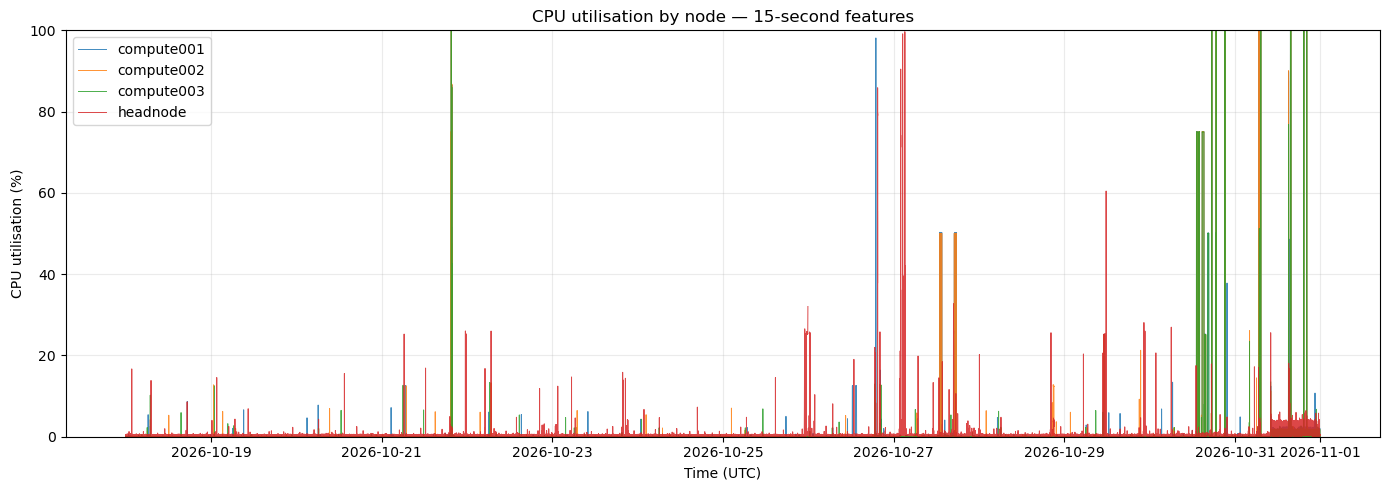

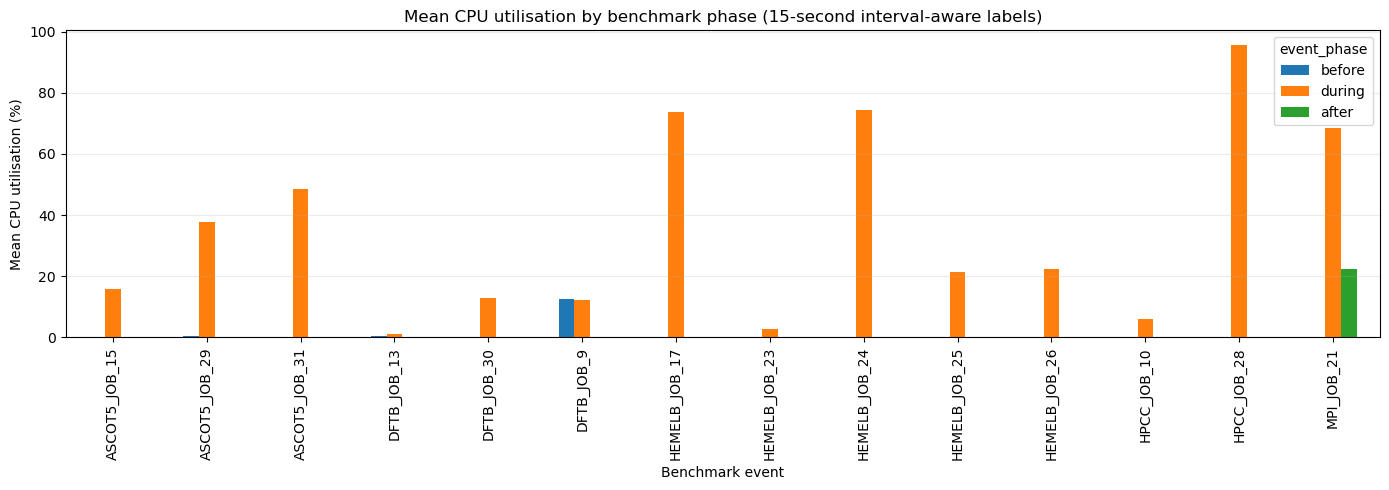

,event_id,event_phase,mean_cpu_pct,sample_count
0,ASCOT5_JOB_15,after,0.018334,20
1,ASCOT5_JOB_15,before,0.036844,19
2,ASCOT5_JOB_15,during,15.803914,2
3,ASCOT5_JOB_29,after,0.037910,20
4,ASCOT5_JOB_29,before,0.282230,20
5,ASCOT5_JOB_29,during,37.810611,1
6,ASCOT5_JOB_31,after,0.047491,20
7,ASCOT5_JOB_31,before,0.022918,20
8,ASCOT5_JOB_31,during,48.635983,1
9,DFTB_JOB_13,after,0.038345,20


In [21]:
plt.figure(figsize=(14, 5))
for node, group in features_15s.groupby("node_id"):
    group = group.sort_values("observation_time")
    plt.plot(group["observation_time"], group["cpu_utilisation_pct"], label=node, linewidth=0.7, alpha=0.85)
plt.title("CPU utilisation by node — 15-second features")
plt.xlabel("Time (UTC)")
plt.ylabel("CPU utilisation (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

if not benchmark_telemetry_15s.empty:
    plot_data = benchmark_telemetry_15s.loc[
        benchmark_telemetry_15s["event_phase"].isin(["before", "during", "after"])
        & ~benchmark_telemetry_15s["confounded_by_other_event"]
    ]
    if not plot_data.empty:
        summary = plot_data.groupby(["event_id", "event_phase"], as_index=False).agg(
            mean_cpu_pct=("cpu_utilisation_pct", "mean"),
            sample_count=("cpu_utilisation_pct", "count"),
        )
        pivot = summary.pivot(index="event_id", columns="event_phase", values="mean_cpu_pct")
        pivot = pivot.reindex(columns=["before", "during", "after"])
        ax = pivot.plot(kind="bar", figsize=(14, 5))
        ax.set_title("Mean CPU utilisation by benchmark phase (15-second interval-aware labels)")
        ax.set_ylabel("Mean CPU utilisation (%)")
        ax.set_xlabel("Benchmark event")
        ax.grid(True, axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()
        display(summary)

## 21. Prepare model-feature candidates (not training)

This section prepares candidate matrices but does not train a model. The initial Isolation Forest is a **compute-resource anomaly model**, so its inputs focus on CPU, memory, network throughput/retransmission, disk activity, load, process pressure and local root-filesystem capacity.

The following are deliberately kept out of this first resource model:

- `nfs_min_available_pct`: its coverage is intermittent on compute002/compute003; it remains in diagnostic tables for a separate shared-storage investigation.
- `rx_errors_per_s`, `tx_errors_per_s`, `rx_drops_per_s`, `tx_drops_per_s`: the audited compute-node values are constant at zero, so they add no information to the first model.
- Collector-health and NFS collector fields: these describe monitoring/observability, not the compute resource state. They remain available in `collector_profile`, `system_features`, `features_15s`, and `collector_context_15s` for dashboarding or a separate monitoring-health experiment.

Rows with `node_up != 1` are excluded. Remaining rows with missing or non-finite resource features are reported and placed in a separate complete-case model-input frame; the source feature table is not altered. Both candidate and ready-frame row counts are reported, so any dropped rows remain auditable.


In [22]:
# --- Replace Cell In [22] (Section 21) ---
MODEL_FEATURE_CANDIDATES = [
    "cpu_utilisation_pct", "cpu_busy_excluding_iowait_pct", "iowait_pct",
    "memory_used_pct", "memory_available_pct", "memory_free_pct",
    "network_rx_mib_s", "network_tx_mib_s", "tcp_retrans_per_s",
    "disk_read_mib_s", "disk_write_mib_s", "disk_io_time_pct_sum", "disk_io_now",
    "node_load1_per_core", "node_load5_per_core", "node_load15_per_core",
    "node_procs_running", "node_procs_blocked",
    "root_filesystem_available_pct", "root_filesystem_used_pct",
]

MODEL_CONTEXT_FEATURES = [
    "active_collectors_expected", "active_collectors_observed",
    "missing_active_collectors", "collector_coverage_pct",
    "failed_active_collectors", "collector_success_min_active",
    "collector_data_quality", "collectors_always_zero_excluded",
    "collectors_low_presence_excluded", "nfs_collector_observed",
    "nfs_collector_success_observed", "nfs_mount_count",
    "nfs_min_available_pct", "nfs_min_available_gib", "nfs_max_available_pct",
]

model_source_15s = features_15s.loc[
    features_15s["node_id"].isin(ALL_NODES) & (features_15s["node_up"] == 1)
].copy()

present_model_candidates = [
    c for c in MODEL_FEATURE_CANDIDATES
    if c in model_source_15s.columns and model_source_15s[c].notna().any()
]
X_candidate_15s = model_source_15s[present_model_candidates].copy()

feature_profile_15s = pd.DataFrame({
    "non_null": X_candidate_15s.notna().sum(),
    "missing_pct": X_candidate_15s.isna().mean() * 100,
    "n_unique": X_candidate_15s.nunique(dropna=True),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, True])

constant_model_features_15s = feature_profile_15s.index[
    (feature_profile_15s["n_unique"] <= 1) | (feature_profile_15s["non_null"] == 0)
].tolist()
model_feature_columns_15s = [
    c for c in present_model_candidates if c not in constant_model_features_15s
]
X_candidate_15s = model_source_15s[model_feature_columns_15s].copy()

finite_mask_15s = np.isfinite(X_candidate_15s.to_numpy(dtype=float, na_value=np.nan)).all(axis=1)
complete_mask_15s = X_candidate_15s.notna().all(axis=1) & finite_mask_15s
X_model_15s = X_candidate_15s.loc[complete_mask_15s].copy()
model_metadata_15s = model_source_15s.loc[complete_mask_15s, ["node_id", "timestamp", "observation_time"]].copy()

model_row_audit_15s = model_source_15s.assign(
    model_row_complete=complete_mask_15s.to_numpy()
).groupby("node_id").agg(
    candidate_rows=("node_id", "size"),
    complete_rows=("model_row_complete", "sum"),
).reset_index()
model_row_audit_15s["excluded_incomplete_rows"] = model_row_audit_15s["candidate_rows"] - model_row_audit_15s["complete_rows"]
model_row_audit_15s["complete_pct"] = 100.0 * model_row_audit_15s["complete_rows"] / model_row_audit_15s["candidate_rows"]

context_cols_15s = [c for c in MODEL_CONTEXT_FEATURES if c in features_15s.columns]
collector_context_15s = features_15s.loc[
    features_15s["node_id"].isin(COMPUTE_NODES),
    ["node_id", "timestamp", "observation_time", *context_cols_15s]
].copy()

# Detect Oct 21 Stress Test from 15s CPU telemetry
oct21_spikes = features_15s.loc[
    features_15s["node_id"].isin(COMPUTE_NODES)
    & (features_15s["observation_time"] >= "2026-10-21 16:45:00+00:00")
    & (features_15s["observation_time"] <= "2026-10-21 20:30:00+00:00")
    & (features_15s["cpu_utilisation_pct"] >= 10.0)
].copy()

stress_rows = []
for node, grp in oct21_spikes.groupby("node_id"):
    s_utc = grp["sample_interval_start"].min() if "sample_interval_start" in grp else grp["observation_time"].min() - pd.Timedelta(seconds=15)
    e_utc = grp["observation_time"].max()
    stress_rows.append({
        "event_id": f"EVT_STRESS_20261021_{node}",
        "node_id": node,
        "event_class": "stress_test",
        "start_utc": s_utc.strftime("%Y-%m-%d %H:%M:%S"),
        "failure_start_utc": np.nan,
        "unavailable_start_utc": np.nan,
        "recovery_start_utc": e_utc.strftime("%Y-%m-%d %H:%M:%S"),
        "end_utc": e_utc.strftime("%Y-%m-%d %H:%M:%S"),
        "is_failure": 0,
        "planned": 1,
        "group_id": "STRESS001",
        "description": f"Oct 21 stress test spike on {node} (peak CPU {grp['cpu_utilisation_pct'].max():.1f}%)",
        "verification_status": "confirmed stress test spike in 15s telemetry",
    })

combined_events_df = pd.concat([operational_events_df, pd.DataFrame(stress_rows)], ignore_index=True)
combined_events_df = combined_events_df.drop_duplicates(subset=["event_id", "node_id"], keep="last")

# Retain ALL nodes for 1-minute aggregation (preserving headnode & EVT004)
model_source_1min = (
    features_1min.loc[features_1min["node_id"].isin(ALL_NODES)]
    .sort_values(["node_id", "minute_utc"])
    .reset_index(drop=True)
    .copy()
)
model_source_1min = model_source_1min.merge(
    nodes_inventory_df[["node_id", "cpu_logical_cores", "memory_total_bytes", "root_disk_bytes"]],
    on="node_id", how="left"
)

df_eng = model_source_1min.copy()
df_eng["node_down_in_minute"] = (df_eng["node_up_min"].fillna(0) < 1).astype(np.int8)
df_eng["scrape_shortfall_in_minute"] = (4 - df_eng["scrape_rows_in_minute"].fillna(0)).clip(lower=0)
df_eng["collector_shortfall_pct_mean"] = 100.0 - df_eng["collector_coverage_pct_mean"].fillna(100.0)
df_eng["failed_active_collectors_max"] = df_eng["failed_active_collectors_max"].fillna(0.0)

BASE_1MIN_COLS = [
    "cpu_utilisation_pct_mean", "cpu_utilisation_pct_max",
    "iowait_pct_mean", "memory_used_pct_mean", "memory_free_pct_mean",
    "network_rx_mib_s_mean", "network_tx_mib_s_mean", "tcp_retrans_per_s_mean",
    "disk_read_mib_s_mean", "disk_write_mib_s_mean", "disk_io_time_pct_sum_mean", "disk_io_now_mean",
    "node_load1_per_core_mean", "node_load5_per_core_mean", "node_load15_per_core_mean",
    "node_procs_running_mean", "node_procs_blocked_mean",
    "root_filesystem_used_pct_mean", "scrape_duration_seconds_max",
]
for col in BASE_1MIN_COLS:
    if col in df_eng.columns:
        df_eng[col] = df_eng.groupby("node_id")[col].transform(lambda s: s.ffill().bfill().fillna(0.0))

df_eng["disk_io_time_pct_sum_mean"] = df_eng["disk_io_time_pct_sum_mean"].clip(upper=100.0)
df_eng["disk_io_now_mean"]          = df_eng["disk_io_now_mean"].clip(upper=50.0)
df_eng["disk_write_mib_s_mean"]     = df_eng["disk_write_mib_s_mean"].clip(upper=50.0)

for col in ["disk_write_mib_s_mean", "disk_io_now_mean", "iowait_pct_mean", "tcp_retrans_per_s_mean"]:
    df_eng[f"is_nonzero_{col}"] = (df_eng[col] > 0).astype(np.int8)

df_eng["memory_used_delta_1h"]  = df_eng.groupby("node_id")["memory_used_pct_mean"].diff(60).fillna(0.0)
df_eng["root_fs_used_delta_1h"] = df_eng.groupby("node_id")["root_filesystem_used_pct_mean"].diff(60).fillna(0.0)

for col in ["cpu_utilisation_pct_mean", "node_load1_per_core_mean", "disk_write_mib_s_mean", "scrape_duration_seconds_max"]:
    peer_med = df_eng.groupby("minute_utc")[col].transform("median")
    df_eng[f"{col}_peer_diff"] = (df_eng[col] - peer_med).abs()

for col in ["node_load1_per_core_mean", "disk_write_mib_s_mean", "scrape_duration_seconds_max"]:
    grp = df_eng.groupby("node_id")[col]
    r_mean = grp.transform(lambda s: s.rolling(15, min_periods=1).mean())
    r_std  = grp.transform(lambda s: s.rolling(15, min_periods=2).std().fillna(0.0))
    df_eng[f"{col}_zscore_15m"] = ((df_eng[col] - r_mean) / (r_std + 1e-4)).clip(-15.0, 15.0)

LOG_FEATURES_V6 = [
    "cpu_utilisation_pct_mean", "network_rx_mib_s_mean", "network_tx_mib_s_mean",
    "iowait_pct_mean", "disk_write_mib_s_mean", "disk_io_time_pct_sum_mean",
    "tcp_retrans_per_s_mean",
]
df_eng[LOG_FEATURES_V6] = np.log1p(df_eng[LOG_FEATURES_V6].clip(lower=0.0))

MODEL_FEATURE_COLUMNS_1MIN = [
    "cpu_utilisation_pct_mean", "iowait_pct_mean", "memory_used_pct_mean",
    "network_rx_mib_s_mean", "network_tx_mib_s_mean", "tcp_retrans_per_s_mean",
    "disk_read_mib_s_mean", "disk_write_mib_s_mean", "disk_io_time_pct_sum_mean",
    "disk_io_now_mean", "node_procs_running_mean",
    "is_nonzero_disk_write_mib_s_mean", "is_nonzero_disk_io_now_mean",
    "is_nonzero_iowait_pct_mean", "is_nonzero_tcp_retrans_per_s_mean",
    "memory_used_delta_1h", "root_fs_used_delta_1h",
    "node_down_in_minute", "scrape_shortfall_in_minute",
    "collector_shortfall_pct_mean", "failed_active_collectors_max",
    "scrape_duration_seconds_max",
    "cpu_utilisation_pct_mean_peer_diff", "node_load1_per_core_mean_peer_diff",
    "disk_write_mib_s_mean_peer_diff", "scrape_duration_seconds_max_peer_diff",
    "node_load1_per_core_mean_zscore_15m", "scrape_duration_seconds_max_zscore_15m",
]

X_candidate_1min = df_eng[MODEL_FEATURE_COLUMNS_1MIN].copy()
minute_finite_mask = np.isfinite(X_candidate_1min.to_numpy(dtype=float, na_value=np.nan)).all(axis=1)
complete_mask_1min = X_candidate_1min.notna().all(axis=1) & minute_finite_mask
X_model_1min = X_candidate_1min.loc[complete_mask_1min].copy()
model_metadata_1min = df_eng.loc[complete_mask_1min, ["node_id", "minute_utc"]].copy()

model_row_audit_1min = df_eng.assign(
    model_row_complete=complete_mask_1min.to_numpy()
).groupby("node_id").agg(
    candidate_rows=("node_id", "size"),
    complete_rows=("model_row_complete", "sum"),
).reset_index()
model_row_audit_1min["excluded_incomplete_rows"] = model_row_audit_1min["candidate_rows"] - model_row_audit_1min["complete_rows"]
model_row_audit_1min["complete_pct"] = 100.0 * model_row_audit_1min["complete_rows"] / model_row_audit_1min["candidate_rows"]

# Build Ground-Truth Labels Table (labels_1min_v6)
op_ev = combined_events_df.copy()
op_ev["start_utc"] = pd.to_datetime(op_ev["start_utc"], utc=True, format="mixed")
op_ev["end_utc"]   = pd.to_datetime(op_ev["end_utc"], utc=True, format="mixed")
op_ev["effective_end_utc"] = op_ev["end_utc"].fillna(op_ev["start_utc"] + pd.Timedelta(minutes=1))

labels_1min = df_eng[["minute_utc", "node_id"]].copy()
labels_1min["operational_event_observed"] = 0
labels_1min["operational_event_window"]   = 0
labels_1min["event_id"]                   = None
labels_1min["event_class"]                = "normal"

for ev in op_ev.itertuples(index=False):
    m_exact = (
        (labels_1min["node_id"] == ev.node_id)
        & (labels_1min["minute_utc"] + pd.Timedelta(minutes=1) > ev.start_utc)
        & (labels_1min["minute_utc"] <= ev.effective_end_utc)
    )
    labels_1min.loc[m_exact, "operational_event_observed"] = 1
    labels_1min.loc[m_exact, "event_id"] = ev.event_id
    labels_1min.loc[m_exact, "event_class"] = ev.event_class

    m_win = (
        (labels_1min["node_id"] == ev.node_id)
        & (labels_1min["minute_utc"] >= ev.start_utc.floor("min") - pd.Timedelta(minutes=5))
        & (labels_1min["minute_utc"] <= ev.effective_end_utc.ceil("min") + pd.Timedelta(minutes=10))
    )
    labels_1min.loc[m_win, "operational_event_window"] = 1

if not benchmark_telemetry_1min.empty:
    bench_during = (
        benchmark_telemetry_1min.loc[benchmark_telemetry_1min["event_phase"].eq("during")]
        .groupby(["node_id", "minute_utc"], as_index=False)["minute_overlap_fraction"]
        .max()
    )
    labels_1min = labels_1min.merge(bench_during, on=["node_id", "minute_utc"], how="left")
    labels_1min["minute_overlap_fraction"] = labels_1min["minute_overlap_fraction"].fillna(0.0)
else:
    labels_1min["minute_overlap_fraction"] = 0.0

labels_1min["is_benchmark_active"] = (labels_1min["minute_overlap_fraction"] > 0).astype(np.int8)
labels_1min["is_unlabelled_stress_burst"] = (
    (df_eng["minute_utc"] < "2026-10-27 19:12:00+00:00")
    & ((df_eng["cpu_utilisation_pct_max"] >= 10.0) | (df_eng["node_load1_per_core_mean"] >= 0.25))
).astype(np.int8)

labels_1min["is_any_anomaly"] = (
    (labels_1min["operational_event_window"] == 1)
    | (labels_1min["is_benchmark_active"] == 1)
    | (labels_1min["is_unlabelled_stress_burst"] == 1)
).astype(np.int8)

labels_1min["exclude_from_normal_train"] = labels_1min["is_any_anomaly"]

labels_1min.to_parquet(OUTPUT_DIR / "labels_1min_v6.parquet", index=False)

## 22. Final quality gates and snapshot verification

The final save gate checks that:

- raw source row count and timestamp bounds have not changed during this run;
- the combined feature key is unique;
- CPU percentage calculations are within bounds after clamping only roundoff within `CPU_PERCENT_ROUNDOFF_TOLERANCE`; the raw calculation remains available for audit;
- one-minute records have the expected key grain;
- benchmark timing exclusions are visible and retained in the audit;
- collector health fields are null when `node_up = 0`;
- zero-capacity swap percentages remain undefined;
- root filesystem and NFS shared storage features are separate;
- no `_x`/`_y` merge suffix collisions remain.

If a gate fails, resolve it before saving derived tables or training a model.

Additional validation checks negative non-null rates, event/node mapping uniqueness, benchmark correlation key uniqueness, per-node missingness, and daily per-node distribution summaries. Daily distribution changes are diagnostics, not automatic anomaly labels.


In [23]:
raw_after = con.execute("""
    SELECT COUNT(*) AS total_rows, MIN(timestamp) AS first_timestamp_unix, MAX(timestamp) AS last_timestamp_unix
    FROM main.raw_hpc_all
""").fetchdf()
raw_unchanged = (
    int(raw_after.loc[0, "total_rows"]) == RAW_ROW_COUNT
    and float(raw_after.loc[0, "first_timestamp_unix"]) == RAW_FIRST_UNIX
    and float(raw_after.loc[0, "last_timestamp_unix"]) == RAW_LAST_UNIX
)

feature_key_unique = not features_15s.duplicated(["node_id", "timestamp"]).any()
minute_key_unique = not features_1min.duplicated(["node_id", "minute_utc"]).any()
benchmark_audit_complete = "exclusion_reason" in events_with_nodes.columns
numeric_feature_values = features_15s.select_dtypes(include=[np.number])
no_infinite_values = not np.isinf(numeric_feature_values.to_numpy(dtype=float, na_value=np.nan)).any()
network_quality_mask = features_15s["network_data_quality"].ne("GOOD") if "network_data_quality" in features_15s else pd.Series(False, index=features_15s.index)
disk_quality_mask = features_15s["disk_data_quality"].ne("GOOD") if "disk_data_quality" in features_15s else pd.Series(False, index=features_15s.index)
network_bad_rates_are_null = all(features_15s.loc[network_quality_mask, c].isna().all() for c in ["network_rx_mib_s", "network_tx_mib_s"] if c in features_15s)
disk_bad_rates_are_null = all(features_15s.loc[disk_quality_mask, c].isna().all() for c in ["disk_read_mib_s", "disk_write_mib_s"] if c in features_15s)

cpu_busy_raw = features_15s["cpu_busy_excluding_iowait_pct_raw"]
cpu_busy_raw_within_tolerance = bool(
    cpu_busy_raw.dropna().between(-CPU_PERCENT_ROUNDOFF_TOLERANCE, 100 + CPU_PERCENT_ROUNDOFF_TOLERANCE).all()
)
collector_health_cols_all = [c for c in ["failed_active_collectors", "collector_success_min_active", "active_collectors_observed", "missing_active_collectors", "collector_coverage_pct", "nfs_collector_success_observed"] if c in features_15s]
node_down_mask = features_15s["node_up"].eq(0) if "node_up" in features_15s else pd.Series(False, index=features_15s.index)
collector_fields_null_when_down = all(features_15s.loc[node_down_mask, c].isna().all() for c in collector_health_cols_all)
swap_zero_capacity = memory_features["swap_total_bytes"].eq(0) & memory_features["swap_free_bytes"].eq(0)
swap_pct_undefined_when_no_capacity = memory_features.loc[swap_zero_capacity, "swap_used_pct"].isna().all()
root_fs_available = features_15s["root_filesystem_available_pct"].notna().any() if "root_filesystem_available_pct" in features_15s else False
nfs_mounts_available = features_15s["nfs_mount_count"].gt(0).any() if "nfs_mount_count" in features_15s else False
no_merge_suffix_collisions = not any(str(c).endswith(("_x", "_y")) for c in features_15s.columns)

# Stronger data validation: rate features must not be negative after reset/gap filtering.
NONNEGATIVE_RATE_FEATURES = [
    "network_rx_mib_s", "network_tx_mib_s", "rx_errors_per_s", "tx_errors_per_s",
    "rx_drops_per_s", "tx_drops_per_s", "tcp_retrans_per_s",
    "disk_read_mib_s", "disk_write_mib_s",
]
negative_rate_counts = {
    c: int((features_15s[c].dropna() < 0).sum())
    for c in NONNEGATIVE_RATE_FEATURES if c in features_15s.columns
}
no_negative_rates = all(v == 0 for v in negative_rate_counts.values())

# Collector gates: covered rows must have health values; down/low-coverage rows must not.
collector_health_cols = [c for c in ["failed_active_collectors", "collector_success_min_active"] if c in features_15s]
collector_usable_mask = (
    features_15s["node_up"].eq(1)
    & features_15s["collector_data_quality"].eq("USABLE")
)
collector_unusable_mask = ~collector_usable_mask
collector_values_present_when_usable = all(
    features_15s.loc[collector_usable_mask, c].notna().all() for c in collector_health_cols
)
collector_values_null_when_unusable = all(
    features_15s.loc[collector_unusable_mask, c].isna().all() for c in collector_health_cols
)
collector_health_logic_ok = bool(collector_values_present_when_usable and collector_values_null_when_unusable)
collector_baseline_presence_ok = bool(
    ((collector_profile["baseline_eligible"] == True)
     == ((collector_profile["max_success"] > 0)
         & (collector_profile["presence_pct"] >= COLLECTOR_MIN_PRESENCE_PCT))).all()
)
nfs_collector_separate_ok = all(
    c in features_15s.columns
    for c in ["nfs_collector_observed", "nfs_collector_success_observed", "nfs_mount_count"]
)

# Dynamic disk expectation: an observed series must never exceed the series
# expected from its per-series first-delta lifecycle. Later-attached devices
# should increase expected counts only from their first usable delta onward.
disk_expected_counts_nonnegative = bool(
    (disk_features["expected_disk_counter_series"] >= 0).all()
    and (disk_features["expected_disk_devices"] >= 0).all()
)
disk_observed_not_above_expected = bool(
    (disk_features["observed_disk_counter_series"] <= disk_features["expected_disk_counter_series"]).all()
)
headnode_disk_lifecycle = disk_features.loc[disk_features["node_id"].eq("headnode")]
headnode_disk_lifecycle_dynamic = bool(
    headnode_disk_lifecycle["expected_disk_devices"].nunique() > 1
    and headnode_disk_lifecycle["expected_disk_devices"].max() >= 2
)

# Ready ML matrices are complete and finite; diagnostics remain separately retained.
model_15s_complete_finite = bool(
    not X_model_15s.empty
    and X_model_15s.notna().all().all()
    and np.isfinite(X_model_15s.to_numpy(dtype=float)).all()
)
model_1min_complete_finite = bool(
    not X_model_1min.empty
    and X_model_1min.notna().all().all()
    and np.isfinite(X_model_1min.to_numpy(dtype=float)).all()
)
model_15s_retention_ok = bool(len(X_model_15s) / max(len(model_source_15s), 1) >= 0.90)
model_1min_retention_ok = bool(len(X_model_1min) / max(len(model_source_1min), 1) >= 0.90)
model_has_no_constant_features = bool(
    all(X_model_15s[c].nunique(dropna=True) > 1 for c in X_model_15s.columns)
)


# Per-node missingness report exposes node-specific gaps hidden by global averages.
missingness_rows = []
for node, group in features_15s.groupby("node_id", sort=True):
    numeric_group = group.select_dtypes(include=[np.number])
    for feature in numeric_group.columns:
        missingness_rows.append({
            "node_id": node,
            "feature": feature,
            "missing_pct": float(numeric_group[feature].isna().mean() * 100),
            "non_null": int(numeric_group[feature].notna().sum()),
        })
missingness_by_node = pd.DataFrame(missingness_rows)
missingness_by_node_summary = missingness_by_node.groupby("node_id", as_index=False).agg(
    numeric_features_checked=("feature", "size"),
    features_with_missing_values=("missing_pct", lambda x: int((x > 0).sum())),
    maximum_feature_missing_pct=("missing_pct", "max"),
)
print("Per-node missingness summary:")
display(missingness_by_node_summary)
print("Features with missing values by node:")
display(missingness_by_node.loc[missingness_by_node["missing_pct"] > 0].sort_values(
    ["node_id", "missing_pct"], ascending=[True, False]
))
print("Negative non-null rate counts:", negative_rate_counts)

# Daily distributions are a diagnostic for drift / workload changes, not an
# automatic anomaly label. Compare nodes and days before deciding to normalize.
daily_source = features_15s.copy()
daily_source["day_utc"] = daily_source["observation_time"].dt.floor("D")
daily_distribution_features = [
    c for c in ["cpu_utilisation_pct", "memory_used_pct", "network_rx_mib_s",
                "network_tx_mib_s", "disk_read_mib_s", "disk_write_mib_s",
                "node_load1_per_core"] if c in daily_source.columns
]
daily_distribution_records = []
for (node, day), group in daily_source.groupby(["node_id", "day_utc"], sort=True):
    record = {"node_id": node, "day_utc": day, "rows": len(group)}
    for col in daily_distribution_features:
        values = group[col].dropna()
        record[f"{col}_non_null"] = len(values)
        record[f"{col}_median"] = values.median() if len(values) else np.nan
        record[f"{col}_p95"] = values.quantile(0.95) if len(values) else np.nan
    daily_distribution_records.append(record)
daily_feature_distribution = pd.DataFrame(daily_distribution_records)
print("Daily per-node feature distributions (inspect for distribution shifts):")
display(daily_feature_distribution.head(20))

event_node_key_unique = not events_with_nodes.loc[
    events_with_nodes["node_id"].notna()
].duplicated(["event_id", "node_id"]).any()
benchmark_15s_key_unique = (
    benchmark_telemetry_15s.empty
    or not benchmark_telemetry_15s.duplicated(["event_id", "node_id", "timestamp"]).any()
)
benchmark_1min_key_unique = (
    benchmark_telemetry_1min.empty
    or not benchmark_telemetry_1min.duplicated(["event_id", "node_id", "minute_utc"]).any()
)

final_gates = pd.DataFrame([
    {"gate":"raw_source_unchanged", "passed":raw_unchanged},
    {"gate":"15s_node_timestamp_unique", "passed":feature_key_unique},
    {"gate":"1min_node_minute_unique", "passed":minute_key_unique},
    {"gate":"no_infinite_numeric_features", "passed":no_infinite_values},
    {"gate":"cpu_percentages_in_range_after_roundoff_only_clamp", "passed":bool(CPU_RANGE_OK)},
    {"gate":"raw_cpu_busy_within_roundoff_tolerance", "passed":cpu_busy_raw_within_tolerance},
    {"gate":"memory_percentages_in_range", "passed":bool(MEMORY_RANGE_OK)},
    {"gate":"network_bad_quality_rates_null", "passed":bool(network_bad_rates_are_null)},
    {"gate":"disk_bad_quality_rates_null", "passed":bool(disk_bad_rates_are_null)},
    {"gate":"collector_fields_null_when_node_down", "passed":bool(collector_fields_null_when_down)},
    {"gate":"collector_presence_baseline_uses_95pct_rule", "passed":collector_baseline_presence_ok},
    {"gate":"collector_health_values_follow_row_coverage_gate", "passed":collector_health_logic_ok},
    {"gate":"nfs_collector_and_mounts_are_separate_features", "passed":nfs_collector_separate_ok},
    {"gate":"dynamic_disk_expected_series_nonnegative", "passed":disk_expected_counts_nonnegative},
    {"gate":"headnode_disk_device_lifecycle_detected", "passed":headnode_disk_lifecycle_dynamic},
    {"gate":"disk_observed_series_not_above_lifecycle_expectation", "passed":disk_observed_not_above_expected},
    {"gate":"swap_percentage_undefined_when_capacity_zero", "passed":bool(swap_pct_undefined_when_no_capacity)},
    {"gate":"root_filesystem_feature_available", "passed":bool(root_fs_available)},
    {"gate":"nfs_mount_feature_available_for_diagnostics", "passed":bool(nfs_mounts_available)},
    {"gate":"no_merge_suffix_collisions", "passed":bool(no_merge_suffix_collisions)},
    {"gate":"nonnegative_network_and_disk_rates", "passed":bool(no_negative_rates)},
    {"gate":"event_node_key_unique", "passed":bool(event_node_key_unique)},
    {"gate":"benchmark_15s_event_node_timestamp_unique", "passed":bool(benchmark_15s_key_unique)},
    {"gate":"benchmark_1min_event_node_minute_unique", "passed":bool(benchmark_1min_key_unique)},
    {"gate":"benchmark_event_audit_present", "passed":benchmark_audit_complete},
    {"gate":"15s_model_matrix_complete_and_finite", "passed":model_15s_complete_finite},
    {"gate":"1min_model_matrix_complete_and_finite", "passed":model_1min_complete_finite},
    {"gate":"15s_model_row_retention_at_least_90pct", "passed":model_15s_retention_ok},
    {"gate":"1min_model_row_retention_at_least_90pct", "passed":model_1min_retention_ok},
    {"gate":"model_matrix_has_no_constant_features", "passed":model_has_no_constant_features},
    {"gate":"event_timezone_reviewed_against_source_logs", "passed":bool(EVENT_TIMEZONE_REVIEWED)},
])
display(final_gates)

PIPELINE_READY_TO_SAVE = bool(final_gates["passed"].all())
print("PIPELINE_READY_TO_SAVE:", PIPELINE_READY_TO_SAVE)
print("Raw row count before:", RAW_ROW_COUNT)
print("Raw row count after:", int(raw_after.loc[0, "total_rows"]))
print("15-second rows:", len(features_15s))
print("One-minute rows:", len(features_1min))
print("Benchmark event-node rows:", len(events_with_nodes))
print("Label-eligible event-node rows:", len(events_label_eligible))
print("Excluded event-node rows:", len(event_exclusions))

Per-node missingness summary:


,node_id,numeric_features_checked,features_with_missing_values,maximum_feature_missing_pct
0,compute001,114,106,100.0
1,compute002,114,106,100.0
2,compute003,114,106,100.0
3,headnode,114,106,100.0


Features with missing values by node:


,node_id,feature,missing_pct,non_null
39,compute001,swap_used_pct,100.000000,0
107,compute001,nfs_min_available_pct,3.774848,77595
108,compute001,nfs_min_available_gib,3.774848,77595
109,compute001,nfs_max_available_pct,3.774848,77595
20,compute001,cpu_utilisation_pct,0.006200,80634
...,...,...,...,...
444,headnode,root_filesystem_used_pct,0.009921,80632
445,headnode,root_filesystem_available_gib,0.009921,80632
446,headnode,root_filesystem_size_gib,0.009921,80632
447,headnode,root_filesystem_records,0.009921,80632


Negative non-null rate counts: {'network_rx_mib_s': 0, 'network_tx_mib_s': 0, 'rx_errors_per_s': 0, 'tx_errors_per_s': 0, 'rx_drops_per_s': 0, 'tx_drops_per_s': 0, 'tcp_retrans_per_s': 0, 'disk_read_mib_s': 0, 'disk_write_mib_s': 0}
Daily per-node feature distributions (inspect for distribution shifts):


,node_id,day_utc,rows,cpu_utilisation_pct_non_null,cpu_utilisation_pct_median,cpu_utilisation_pct_p95,memory_used_pct_non_null,memory_used_pct_median,memory_used_pct_p95,network_rx_mib_s_non_null,...,network_tx_mib_s_p95,disk_read_mib_s_non_null,disk_read_mib_s_median,disk_read_mib_s_p95,disk_write_mib_s_non_null,disk_write_mib_s_median,disk_write_mib_s_p95,node_load1_per_core_non_null,node_load1_per_core_median,node_load1_per_core_p95
0,compute001,2026-10-18 00:00:00+00:00,5760,5759,0.016669,0.041646,5760,2.634924,2.647265,5759,...,0.000911,5759,0.0,0.0,5759,0.000000,0.000521,5760,0.000,0.00125
1,compute001,2026-10-19 00:00:00+00:00,5760,5760,0.016668,0.033339,5760,2.642607,2.668045,5760,...,0.000912,5760,0.0,0.0,5760,0.000000,0.000521,5760,0.000,0.00125
2,compute001,2026-10-20 00:00:00+00:00,5760,5760,0.016669,0.033350,5760,2.653314,2.672752,5760,...,0.000912,5760,0.0,0.0,5760,0.000000,0.000521,5760,0.000,0.00125
3,compute001,2026-10-21 00:00:00+00:00,5760,5760,0.016669,0.041653,5760,2.672082,2.722044,5760,...,0.000913,5760,0.0,0.0,5760,0.000000,0.001042,5760,0.000,0.00125
4,compute001,2026-10-22 00:00:00+00:00,5760,5760,0.016668,0.041649,5760,2.700800,2.718605,5760,...,0.000919,5760,0.0,0.0,5760,0.000000,0.000781,5760,0.000,0.00125
5,compute001,2026-10-23 00:00:00+00:00,5760,5760,0.016668,0.033344,5760,2.707825,2.724922,5760,...,0.000919,5760,0.0,0.0,5760,0.000000,0.000521,5760,0.000,0.00000
6,compute001,2026-10-24 00:00:00+00:00,5760,5760,0.016669,0.041653,5760,2.701215,2.726873,5760,...,0.000919,5760,0.0,0.0,5760,0.000000,0.000521,5760,0.000,0.00000
7,compute001,2026-10-25 00:00:00+00:00,5760,5760,0.016669,0.033347,5760,2.710702,2.717385,5760,...,0.000919,5760,0.0,0.0,5760,0.000000,0.000521,5760,0.000,0.00000
8,compute001,2026-10-26 00:00:00+00:00,5760,5760,0.016672,0.050000,5760,2.718507,2.915599,5760,...,0.000920,5760,0.0,0.0,5760,0.000000,0.001563,5760,0.000,0.00625
9,compute001,2026-10-27 00:00:00+00:00,5759,5755,0.025004,0.058374,5757,2.898648,3.021059,5755,...,0.001490,5755,0.0,0.0,5755,0.001042,0.012240,5757,0.375,0.38375


,gate,passed
0,raw_source_unchanged,True
1,15s_node_timestamp_unique,True
2,1min_node_minute_unique,True
3,no_infinite_numeric_features,True
4,cpu_percentages_in_range_after_roundoff_only_c...,True
5,raw_cpu_busy_within_roundoff_tolerance,True
6,memory_percentages_in_range,True
7,network_bad_quality_rates_null,True
8,disk_bad_quality_rates_null,True
9,collector_fields_null_when_node_down,True


PIPELINE_READY_TO_SAVE: True
Raw row count before: 49616574
Raw row count after: 49616574
15-second rows: 322557
One-minute rows: 80640
Benchmark event-node rows: 44
Label-eligible event-node rows: 29
Excluded event-node rows: 15


## 23. Save derived Parquet files and DuckDB tables (explicit opt-in)

Saving is disabled by default. After reviewing all previous outputs, change `SAVE_OUTPUTS = True` in Section 1 and rerun from the top. This section writes only the named derived feature tables and Parquet files. It does not alter any raw or benchmark annotation table.

If the final gates fail, saving is refused. This is intentional: do not persist a known-invalid feature set as the current approved output.

On explicit saves, optional outputs that are empty on the current run have any stale V6 DuckDB table and Parquet file removed. Every output receives a write-status record in the run manifest.


The V6 save manifest includes the complete-case 15-second and one-minute model-input matrices, plus separate collector/NFS context outputs. The primary model matrices exclude NFS capacity, constant network error/drop counters and collector-health context; those remain available for diagnostic analysis.

In [ ]:
# Define ENVIRONMENT_SNAPSHOT if it was omitted from Cell In [2]
try:
    _pip_freeze = subprocess.run(
        [sys.executable, "-m", "pip", "freeze", "--local"],
        capture_output=True, text=True, check=False
    )
    PIP_FREEZE_LINES = _pip_freeze.stdout.splitlines() if _pip_freeze.returncode == 0 else []
except Exception:
    PIP_FREEZE_LINES = []

ENVIRONMENT_SNAPSHOT = {
    "python_version": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "duckdb_version": duckdb.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "pip_freeze": PIP_FREEZE_LINES,
}

if not SAVE_OUTPUTS:
    print("SAVE_OUTPUTS is False. No Parquet files or DuckDB feature tables were written.")
elif not PIPELINE_READY_TO_SAVE:
    raise RuntimeError("Final quality gates failed. Resolve the failures before saving feature outputs.")
else:
    outputs = [
        (cpu_features, "cpu_features_15s_v6", "cpu_features_15s_v6.parquet", True),
        (memory_features, "memory_features_15s_v6", "memory_features_15s_v6.parquet", True),
        (network_features, "network_features_15s_v6", "network_features_15s_v6.parquet", True),
        (disk_features, "disk_features_15s_v6", "disk_features_15s_v6.parquet", True),
        (system_features, "system_features_15s_v6", "system_features_15s_v6.parquet", True),
        (filesystem_features, "filesystem_features_15s_v6", "filesystem_features_15s_v6.parquet", True),
        (features_15s, "hpc_features_15s_v6", "hpc_features_15s_v6.parquet", True),
        (features_1min, "hpc_features_1min_v6", "hpc_features_1min_v6.parquet", True),
        (collector_profile, "collector_profile_v6", "collector_profile_v6.parquet", True),
        (nfs_collector_mount_audit, "nfs_collector_mount_audit_v6", "nfs_collector_mount_audit_v6.parquet", False),
        (collector_context_15s, "collector_context_15s_v6", "collector_context_15s_v6.parquet", False),
        (
            X_model_15s.assign(
                node_id=model_metadata_15s["node_id"].to_numpy(),
                timestamp=model_metadata_15s["timestamp"].to_numpy(),
            ),
            "model_input_15s_v6",
            "model_input_15s_v6.parquet",
            True,
        ),
        (
            X_model_1min.assign(
                node_id=model_metadata_1min["node_id"].to_numpy(),
                minute_utc=model_metadata_1min["minute_utc"].to_numpy(),
            ),
            "model_input_1min_v6",
            "model_input_1min_v6.parquet",
            True,
        ),
        (labels_1min, "labels_1min_v6", "labels_1min_v6.parquet", True),
        (nodes_inventory_df, "node_inventory_v6", "node_inventory_v6.parquet", True),
        (events_with_nodes, "benchmark_event_audit_v6", "benchmark_event_audit_v6.parquet", True),
        (event_exclusions, "benchmark_event_exclusions_v6", "benchmark_event_exclusions_v6.parquet", False),
        (known_execution_markers, "benchmark_execution_markers_v6", "benchmark_execution_markers_v6.parquet", False),
        (event_overlaps, "benchmark_event_overlaps_v6", "benchmark_event_overlaps_v6.parquet", False),
        (benchmark_telemetry_15s, "benchmark_telemetry_15s_v6", "benchmark_telemetry_15s_v6.parquet", False),
        (benchmark_telemetry_1min, "benchmark_telemetry_1min_v6", "benchmark_telemetry_1min_v6.parquet", False),
        (daily_feature_distribution, "daily_feature_distribution_v6", "daily_feature_distribution_v6.parquet", False),
    ]

    output_write_audit = []
    for frame, table_name, parquet_name, required in outputs:
        parquet_path = OUTPUT_DIR / parquet_name
        is_empty = frame is None or frame.empty
        if is_empty and required:
            raise RuntimeError(f"Required output {table_name} is empty; refusing to save an incomplete run.")
        if is_empty:
            con.execute(f"DROP TABLE IF EXISTS main.{table_name}")
            parquet_path.unlink(missing_ok=True)
            status = "EMPTY_REMOVED_STALE_TABLE_AND_PARQUET"
            print(f"{table_name}: empty; removed any stale table/file from a previous run.")
        else:
            save_feature_output(frame, table_name, parquet_name)
            status = "WRITTEN_CURRENT_RUN"
        output_write_audit.append({
            "table_name": table_name,
            "parquet_name": parquet_name,
            "rows": 0 if is_empty else int(len(frame)),
            "status": status,
        })

    combined_events_df.to_csv(OUTPUT_DIR / "events.csv", index=False)
    print("Saved updated events.csv (including Oct 21 stress test) to:", OUTPUT_DIR / "events.csv")

    output_write_audit_df = pd.DataFrame(output_write_audit)
    display(output_write_audit_df)

    run_manifest = {
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "environment": ENVIRONMENT_SNAPSHOT,
        "database_path": str(DB_PATH),
        "raw_rows": RAW_ROW_COUNT,
        "raw_first_timestamp_unix": RAW_FIRST_UNIX,
        "raw_last_timestamp_unix": RAW_LAST_UNIX,
        "naive_event_timezone": EVENT_TIMEZONE_FOR_NAIVE,
        "event_timezone_reviewed": EVENT_TIMEZONE_REVIEWED,
        "selected_network_interfaces": selected_interfaces,
        "excluded_event_ids_from_labels": sorted(EVENTS_EXCLUDED_FROM_LABELS),
        "pipeline_version": "v6",
        "features_15s_shape": list(features_15s.shape),
        "features_1min_shape": list(features_1min.shape),
        "model_features_15s": model_feature_columns_15s,
        "model_features_1min": MODEL_FEATURE_COLUMNS_1MIN,
        "model_input_15s_shape": list(X_model_15s.shape),
        "model_input_1min_shape": list(X_model_1min.shape),
        "model_row_audit_15s": model_row_audit_15s.to_dict(orient="records"),
        "model_row_audit_1min": model_row_audit_1min.to_dict(orient="records"),
        "phase_support_thresholds": {
            "15s_intervals": MIN_15S_PHASE_INTERVALS_FOR_DESCRIPTIVE_SUMMARY,
            "1min_rows": MIN_1MIN_PHASE_ROWS_FOR_DESCRIPTIVE_SUMMARY,
        },
        "negative_rate_counts": negative_rate_counts,
        "final_gates": final_gates.to_dict(orient="records"),
        "output_write_audit": output_write_audit,
    }
    manifest_path = OUTPUT_DIR / "feature_pipeline_v6_run_manifest.json"
    manifest_path.write_text(json.dumps(run_manifest, indent=2, default=str), encoding="utf-8")
    print("Run manifest:", manifest_path)

Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved cpu_features_15s_v6: 322,540 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\cpu_features_15s_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved memory_features_15s_v6: 322,544 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\memory_features_15s_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved network_features_15s_v6: 322,540 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\network_features_15s_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Ad

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved hpc_features_15s_v6: 322,557 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\hpc_features_15s_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved hpc_features_1min_v6: 80,640 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\hpc_features_1min_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved collector_profile_v6: 198 rows → C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\collector_profile_v6.parquet
Saved updated events.csv (including Oct 21 stress test) to: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\events.csv
Saved nfs_collector_mount_audit_v6: 7 rows → C:\Users\Admin\Documents\chpc\capstone pr

,table_name,parquet_name,rows,status
0,cpu_features_15s_v6,cpu_features_15s_v6.parquet,322540,WRITTEN_CURRENT_RUN
1,memory_features_15s_v6,memory_features_15s_v6.parquet,322544,WRITTEN_CURRENT_RUN
2,network_features_15s_v6,network_features_15s_v6.parquet,322540,WRITTEN_CURRENT_RUN
3,disk_features_15s_v6,disk_features_15s_v6.parquet,322540,WRITTEN_CURRENT_RUN
4,system_features_15s_v6,system_features_15s_v6.parquet,322557,WRITTEN_CURRENT_RUN
5,filesystem_features_15s_v6,filesystem_features_15s_v6.parquet,322544,WRITTEN_CURRENT_RUN
6,hpc_features_15s_v6,hpc_features_15s_v6.parquet,322557,WRITTEN_CURRENT_RUN
7,hpc_features_1min_v6,hpc_features_1min_v6.parquet,80640,WRITTEN_CURRENT_RUN
8,collector_profile_v6,collector_profile_v6.parquet,198,WRITTEN_CURRENT_RUN
9,nfs_collector_mount_audit_v6,nfs_collector_mount_audit_v6.parquet,7,WRITTEN_CURRENT_RUN


NameError: name 'ENVIRONMENT_SNAPSHOT' is not defined

## 24. Close DuckDB

Close the connection when all checks and any optional save have completed. The raw DuckDB source tables and benchmark annotations remain unchanged.

In [ ]:
con.close()
print("DuckDB connection closed.")